In [ ]:

import numpy as np
import pandas as pd

from lifelines import CoxPHFitter
from lifelines import KaplanMeierFitter
from lifelines import AalenJohansenFitter

In [175]:
import os
import re
import numpy as np
import pandas as pd

pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 200)

# Paths:
DATA_DIR = os.path.join('..', 'data')
OUT_DIR  = os.path.join('..', 'output')
os.makedirs(OUT_DIR, exist_ok=True)

NACC_MAIN_PATH = os.path.join(DATA_DIR, 'investigator_nacc72.csv')

USE_ONLY_V3 = False   # True => keep only FORMVER in {3, 3.2}

# Horizon sweep range
MIN_H = 3
MAX_H = 12

In [176]:
df = pd.read_csv(NACC_MAIN_PATH, low_memory=False)
df['NACCID'] = df['NACCID'].astype(str)

def make_visit_date(df_: pd.DataFrame) -> pd.Series:
    y = pd.to_numeric(df_['VISITYR'], errors='coerce')
    m = pd.to_numeric(df_['VISITMO'], errors='coerce').fillna(6).astype(int).clip(1, 12)
    d = pd.to_numeric(df_['VISITDAY'], errors='coerce').fillna(15).astype(int).clip(1, 28)
    return pd.to_datetime(dict(year=y, month=m, day=d), errors='coerce')

df['visit_date'] = make_visit_date(df)
df = df.dropna(subset=['NACCID', 'visit_date']).copy()
df = df.sort_values(['NACCID', 'visit_date']).reset_index(drop=True)

if 'FORMVER' in df.columns:
    df['FORMVER'] = pd.to_numeric(df['FORMVER'], errors='coerce')

print('Rows:', len(df), 'Participants:', df['NACCID'].nunique())
df[['NACCID','visit_date'] + ([ 'FORMVER' ] if 'FORMVER' in df.columns else [])].head()

Rows: 207454 Participants: 55268


,NACCID,visit_date,FORMVER
0,NACC000011,2006-04-17,1.0
1,NACC000011,2007-06-18,1.0
2,NACC000011,2008-06-03,2.0
3,NACC000011,2009-08-03,2.0
4,NACC000034,2015-07-16,3.0


In [ ]:
# =========================================================
# NACC special-code cleanup + harmonization
# =========================================================

df = df.copy()

# Replace structural missing code -4 with NaN everywhere numeric
for col in df.columns:
    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].replace(-4, np.nan)

# replace common generic unknown codes 
COMMON_UNKNOWN_CODES = {8, 9, 88, 99, 888, 999, 8888, 9999}

vars_to_soft_clean = [
    "DIABETES", "DIABET",
    "CVAFIB", "AFIBRILL",
    "APNEA", "SLEEPAP",
    "HYPERTEN", "HYPERT",
    "HYPERCHO", "HYPCHOL",
    "CBSTROKE", "CBTIA",
    "CVDSIGNS", "POSTINST",
    "NACCMMSE", "CDRSUM", "NACCAGE", "EDUC"
]

for col in vars_to_soft_clean:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
        df[col] = df[col].replace(list(COMMON_UNKNOWN_CODES), np.nan)

# 3) Harmonize cross-version medical variables
def combine_binary_cols(df_in, cols, new_name):
    present = [c for c in cols if c in df_in.columns]
    if len(present) == 0:
        return df_in
    x = df_in[present].copy()
    # treat positive values as present, zeros as absent, NaN ignored
    x = x.apply(pd.to_numeric, errors="coerce")
    df_in[new_name] = np.where((x == 1).any(axis=1), 1,
                         np.where((x == 0).any(axis=1), 0, np.nan))
    return df_in

df = combine_binary_cols(df, ["DIABETES", "DIABET"], "diabetes_any")
df = combine_binary_cols(df, ["CVAFIB", "AFIBRILL"], "afib_any")
df = combine_binary_cols(df, ["APNEA", "SLEEPAP"], "sleep_apnea_any")
df = combine_binary_cols(df, ["HYPERTEN", "HYPERT"], "htn_any")
df = combine_binary_cols(df, ["HYPERCHO", "HYPCHOL"], "hyperchol_any")

print("Harmonized columns created:")
for c in ["diabetes_any", "afib_any", "sleep_apnea_any", "htn_any", "hyperchol_any"]:
    if c in df.columns:
        print(c, df[c].value_counts(dropna=False).to_dict())

Harmonized columns created:
diabetes_any {0.0: 178333, 1.0: 16658, nan: 12463}
afib_any {0.0: 188667, 1.0: 15001, nan: 3786}
sleep_apnea_any {nan: 106691, 0.0: 80049, 1.0: 20714}
htn_any {1.0: 104806, 0.0: 96524, nan: 6124}
hyperchol_any {1.0: 109121, 0.0: 89653, nan: 8680}


C:\Users\branjan\AppData\Local\Temp\ipykernel_18456\2306927205.py:41: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_in[new_name] = np.where((x == 1).any(axis=1), 1,
C:\Users\branjan\AppData\Local\Temp\ipykernel_18456\2306927205.py:41: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_in[new_name] = np.where((x == 1).any(axis=1), 1,
C:\Users\branjan\AppData\Local\Temp\ipykernel_18456\2306927205.py:41: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has 

In [178]:


if "DEMENTED" in df.columns:
    no_dem_mask = df["DEMENTED"] == 0
else:
    no_dem_mask = pd.Series(True, index=df.index)

if "NACCUDSD" in df.columns:
    cnmci_mask = df["NACCUDSD"].isin([1,2,3])
else:
    cn_mask = (df["NORMCOG"] == 1) if "NORMCOG" in df.columns else pd.Series(False, index=df.index)
    mci_mask = df["NACCTMCI"].isin([1,2,3,4]) if "NACCTMCI" in df.columns else pd.Series(False, index=df.index)

    if ("NORMCOG" in df.columns) or ("NACCTMCI" in df.columns):
        cnmci_mask = cn_mask | mci_mask
    else:
        cnmci_mask = pd.Series(True, index=df.index)

eligible = df[no_dem_mask & cnmci_mask].copy()

baseline = (
    eligible
    .sort_values(["NACCID","visit_date"])
    .groupby("NACCID", as_index=False)
    .first()
)

baseline = baseline[["NACCID","visit_date"]]
baseline = baseline.rename(columns={"visit_date":"baseline_date"})

print("Baseline participants:", len(baseline))
baseline.head()

/var/folders/nq/q3v4dg_s4q78s4w9bbr8zsv40000gn/T/ipykernel_27548/2428668717.py:23: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .first()


Baseline participants: 38341


,NACCID,baseline_date
0,NACC000011,2006-04-17
1,NACC000034,2015-07-16
2,NACC000067,2012-05-23
3,NACC000073,2016-05-20
4,NACC000138,2023-07-13


In [179]:
def years_between(a: pd.Series, b: pd.Series) -> pd.Series:
    return (b - a).dt.days / 365.25

keep_ids = set(baseline['NACCID'])
df2 = df[df['NACCID'].isin(keep_ids)].merge(
    baseline[['NACCID','baseline_date']], on='NACCID', how='left'
).copy()

df2['t_years'] = years_between(df2['baseline_date'], df2['visit_date'])
post = df2[df2['t_years'] > 0].copy()

print("=== CHECKPOINT: post ===")
print("baseline N:", baseline["NACCID"].nunique())
print("post rows:", len(post), " post unique IDs:", post["NACCID"].nunique())
print("post visit_date min/max:", post["visit_date"].min(), post["visit_date"].max())
print("t_years min/max:", post["t_years"].min(), post["t_years"].max())

max_follow = post.groupby('NACCID')['t_years'].max().rename('max_follow_years')
baseline2 = baseline.merge(max_follow, on='NACCID', how='left')

print("\n=== CHECKPOINT: follow-up ===")
print("max_follow_years describe:")
display(baseline2["max_follow_years"].describe())
print("eligible @4y:", (baseline2["max_follow_years"] >= 4).sum())
print("eligible @5y:", (baseline2["max_follow_years"] >= 5).sum())

baseline2['max_follow_years'] = baseline2['max_follow_years'].fillna(0)

#DEMENTED: 0-No, 1-Yes
#NACCUDSD:1-Normal, 2-Impaired not MCI, 3-MCI, 4-Dementia
# if 'NACCUDSD' in post.columns:
#     dem_events_all = post[post['NACCUDSD'] == 4].copy()
#     dementia_def = 'NACCUDSD==4'
# else:
#     dem_events_all = post[post['DEMENTED'] == 1].copy()
#     dementia_def = 'DEMENTED==1'

def get_dementia_events(df_in):
    if "DEMENTED" in df_in.columns:
        return df_in[df_in["DEMENTED"] == 1].copy(), "DEMENTED==1"
    elif "NACCUDSD" in df_in.columns:
        return df_in[df_in["NACCUDSD"] == 4].copy(), "NACCUDSD==4"
    else:
        raise KeyError("Neither DEMENTED nor NACCUDSD found.")
    

dem_events_all, dementia_def = get_dementia_events(post)
first_dem_ever = (dem_events_all.sort_values(['NACCID','visit_date'])
                           .groupby('NACCID', as_index=False)
                           .first()
                           .rename(columns={'visit_date':'dementia_date'}))

first_dem_ever = first_dem_ever.merge(
    baseline2[['NACCID', 'baseline_date', 'max_follow_years']],
    on='NACCID',
    how='left',
    suffixes=('', '_base')   # prevent baseline_date_x/y
)

# Normalizing baseline_date if it got duplicated:
if 'baseline_date' not in first_dem_ever.columns:
    for c in ['baseline_date_base', 'baseline_date_x', 'baseline_date_y']:
        if c in first_dem_ever.columns:
            first_dem_ever['baseline_date'] = first_dem_ever[c]
            break
        
first_dem_ever['time_to_dem_years'] = years_between(first_dem_ever['baseline_date'], first_dem_ever['dementia_date'])

print("\n=== CHECKPOINT: first_dem_ever ===")
print("first_dem_ever unique IDs:", first_dem_ever["NACCID"].nunique())
print("time_to_dem_years min/median/max:",
      first_dem_ever["time_to_dem_years"].min(),
      first_dem_ever["time_to_dem_years"].median(),
      first_dem_ever["time_to_dem_years"].max())

print('Dementia event definition:', dementia_def)
print('Participants with ANY post-baseline dementia event:', first_dem_ever['NACCID'].nunique())
first_dem_ever[['NACCID','baseline_date','dementia_date','time_to_dem_years']].head()

=== CHECKPOINT: post ===
baseline N: 38341
post rows: 123654  post unique IDs: 27703
post visit_date min/max: 2006-04-03 00:00:00 2025-10-21 00:00:00
t_years min/max: 0.008213552361396304 19.392197125256672

=== CHECKPOINT: follow-up ===
max_follow_years describe:


count    27703.000000
mean         5.499126
std          4.268776
min          0.109514
25%          2.080767
50%          4.301164
75%          7.685147
max         19.392197
Name: max_follow_years, dtype: float64

eligible @4y: 14853
eligible @5y: 12474

=== CHECKPOINT: first_dem_ever ===
first_dem_ever unique IDs: 5502
time_to_dem_years min/median/max: 0.4188911704312115 2.6885694729637235 19.304585900068446
Dementia event definition: DEMENTED==1
Participants with ANY post-baseline dementia event: 5502


C:\Users\branjan\AppData\Local\Temp\ipykernel_18456\2108224931.py:50: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .first()


,NACCID,baseline_date,dementia_date,time_to_dem_years
0,NACC000034,2015-07-16,2021-05-21,5.848049
1,NACC000162,2009-03-10,2017-11-10,8.670773
2,NACC000225,2009-09-23,2017-07-07,7.786448
3,NACC000271,2007-06-20,2009-05-14,1.900068
4,NACC000333,2021-05-13,2024-07-24,3.197810


In [180]:
# def subtype_primary(row):
#     # Alzheimer's disease
#     if "NACCALZD" in row and row["NACCALZD"] == 1:
#         return "AD"

#     # Lewy body disease
#     if "NACCLBDE" in row and row["NACCLBDE"] == 1:
#         return "PD_LBD"

#     # Vascular brain injury
#     if "CVD" in row and row["CVD"] == 1:
#         return "Vascular"

#     return "Other/Unk"


# def subtype_anymention(row):
#     if ("NACCALZD" in row and row["NACCALZD"] == 1):
#         return "AD"

#     if ("NACCLBDE" in row and row["NACCLBDE"] == 1):
#         return "PD_LBD"

#     if ("CVD" in row and row["CVD"] == 1):
#         return "Vascular"

#     return "Other/Unk"


# def subtype_contributing(row):
#     if "NACCALZP" in row and row["NACCALZP"] in [1,2]:
#         return "AD"

#     if "NACCLBDP" in row and row["NACCLBDP"] in [1,2]:
#         return "PD_LBD"

#     if "CVDIF" in row and row["CVDIF"] in [1,2]:
#         return "Vascular"

#     return "Other/Unk"

In [181]:
# first_dem_ever["subtype_primary"] = first_dem_ever.apply(subtype_primary, axis=1)
# first_dem_ever["subtype_any"]     = first_dem_ever.apply(subtype_anymention, axis=1)
# first_dem_ever["subtype_contrib"] = first_dem_ever.apply(subtype_contributing, axis=1)

# first_dem_ever["subtype_primary_contrib"] = np.where(
#     first_dem_ever["subtype_primary"].eq("Other/Unk"),
#     first_dem_ever["subtype_contrib"],
#     first_dem_ever["subtype_primary"],
# )

# first_dem_ever["subtype_primary_contrib_any"] = np.where(
#     first_dem_ever["subtype_primary_contrib"].eq("Other/Unk"),
#     first_dem_ever["subtype_any"],
#     first_dem_ever["subtype_primary_contrib"],
# )

In [182]:
def subtype_primary(row):

    formver = row.get("FORMVER", np.nan)

    # PD / LBD
    if pd.notna(row.get("NACCETPR")) and int(row["NACCETPR"]) == 2:
        return "PD_LBD"

    # Vascular
    if pd.notna(row.get("NACCETPR")) and int(row["NACCETPR"]) == 8:
        return "Vascular"

    # AD
    if pd.notna(row.get("NACCETPR")) and int(row["NACCETPR"]) == 1:
        return "AD"

    return "Other/Unk"


# Stage 1: Primary
first_dem_ever["subtype_primary_contrib_any"] = first_dem_ever.apply(subtype_primary, axis=1)


print("\nFinal (Primary -> Contrib -> Any) subtype counts:")
display(first_dem_ever["subtype_primary_contrib_any"].value_counts())


Final (Primary -> Contrib -> Any) subtype counts:


subtype_primary_contrib_any
AD           4218
Other/Unk     651
PD_LBD        374
Vascular      259
Name: count, dtype: int64

In [183]:

# Building survival dataset

surv = baseline2[["NACCID", "baseline_date", "max_follow_years"]].copy()

surv = surv.merge(
    first_dem_ever[[
        "NACCID",
        "dementia_date",
        "time_to_dem_years",
        "subtype_primary_contrib_any"
    ]],
    on="NACCID",
    how="left"
)

# Event indicator
surv["event_observed"] = surv["dementia_date"].notna().astype(int)

# Time-to-event
surv["time_to_event"] = np.where(
    surv["event_observed"] == 1,
    surv["time_to_dem_years"],
    surv["max_follow_years"]
)

# Event subtype
surv["event_type"] = np.where(
    surv["event_observed"] == 1,
    surv["subtype_primary_contrib_any"],
    "Censored"
)

print("Survival dataset size:", len(surv))
print(surv["event_type"].value_counts(dropna=False))
surv.head()

Survival dataset size: 38341
event_type
Censored     32839
AD            4218
Other/Unk      651
PD_LBD         374
Vascular       259
Name: count, dtype: int64


,NACCID,baseline_date,max_follow_years,dementia_date,time_to_dem_years,subtype_primary_contrib_any,event_observed,time_to_event,event_type
0,NACC000011,2006-04-17,3.296372,NaT,NaN,NaN,0,3.296372,Censored
1,NACC000034,2015-07-16,6.986995,2021-05-21,5.848049,AD,1,5.848049,AD
2,NACC000067,2012-05-23,2.088980,NaT,NaN,NaN,0,2.088980,Censored
3,NACC000073,2016-05-20,0.000000,NaT,NaN,NaN,0,0.000000,Censored
4,NACC000138,2023-07-13,1.043121,NaT,NaN,NaN,0,1.043121,Censored


In [184]:
# Removing zero follow-up rows
surv = surv[surv["time_to_event"] > 0].copy()


surv_main = surv[surv["event_type"].isin(["Censored", "AD", "PD_LBD", "Vascular"])].copy()

# Any-dementia event
surv_main["event_any_dementia"] = (surv_main["event_type"] != "Censored").astype(int)

print("After cleanup:", len(surv_main))
print(surv_main["event_type"].value_counts(dropna=False))
print(surv_main["event_any_dementia"].value_counts(dropna=False))

After cleanup: 27052
event_type
Censored    22201
AD           4218
PD_LBD        374
Vascular      259
Name: count, dtype: int64
event_any_dementia
0    22201
1     4851
Name: count, dtype: int64


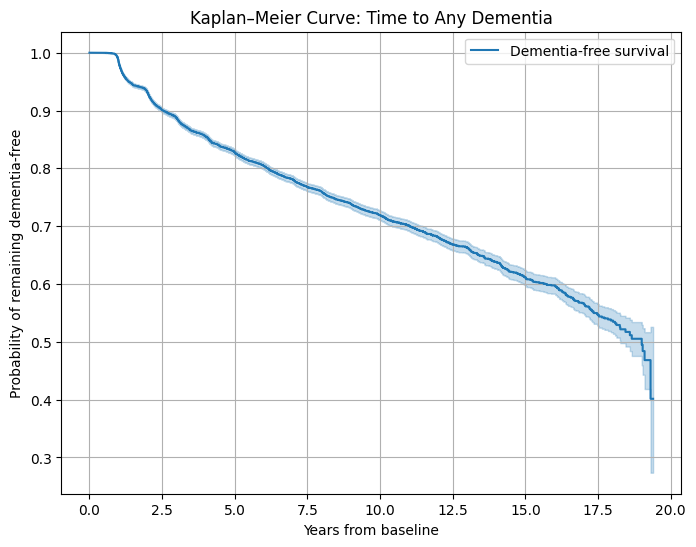

In [185]:
from lifelines import KaplanMeierFitter
import matplotlib.pyplot as plt

kmf = KaplanMeierFitter()

kmf.fit(
    durations=surv_main["time_to_event"],
    event_observed=surv_main["event_any_dementia"],
    label="Dementia-free survival"
)

plt.figure(figsize=(8,6))
kmf.plot_survival_function()
plt.title("Kaplan–Meier Curve: Time to Any Dementia")
plt.xlabel("Years from baseline")
plt.ylabel("Probability of remaining dementia-free")
plt.grid(True)
plt.show()

In [186]:
# cox_features = [
#     "NACCAGE",     
#     "SEX",
#     "EDUC",
#     "NACCMMSE",     
#     "CDRSUM",
#     "DIABETES",
#     "HYPERTEN",
#     "HYPERCHO",
#     "CBSTROKE",
#     "CVAFIB",
#     "DEP2YRS",
#     "APNEA"
# ]

cox_features = [
    "NACCAGE",
    "SEX",
    "EDUC",
    "NACCMMSE",
    "CDRSUM",
    "DEP2YRS",

    # harmonized vascular / metabolic
    "diabetes_any",
    "htn_any",
    "hyperchol_any",
    "afib_any",
    "sleep_apnea_any",

    # cerebrovascular / neuro exam
    "CBSTROKE",
    "CVDSIGNS",
    "POSTINST"
]

In [187]:
baseline_full = (
    df[df["NACCID"].isin(baseline["NACCID"])]
    .sort_values(["NACCID", "visit_date"])
    .groupby("NACCID", as_index=False)
    .first()
)

print("Baseline rows with predictors:", len(baseline_full))
baseline_full.head()

C:\Users\branjan\AppData\Local\Temp\ipykernel_18456\1996829506.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .first()


Baseline rows with predictors: 38341


,NACCID,NACCADC,PACKET,FORMVER,VISITMO,VISITDAY,VISITYR,NACCVNUM,NACCAVST,NACCNVST,NACCDAYS,NACCFDYS,NACCCORE,NACCREAS,NACCREFR,BIRTHMO,BIRTHYR,SEX,HISPANIC,HISPOR,HISPORX,RACE,RACEX,RACESEC,RACESECX,RACETER,RACETERX,PRIMLANG,PRIMLANX,EDUC,MARISTAT,NACCLIVS,INDEPEND,RESIDENC,HANDED,INBIRMO,INBIRYR,INSEX,NEWINF,INHISP,INHISPOR,INHISPOX,NACCNINR,INRACE,INRACEX,INRASEC,INRASECX,INRATER,INRATERX,INEDUC,INRELTO,INRELTOX,INKNOWN,INLIVWTH,INVISITS,INCALLS,INRELY,NACCFAM,NACCMOM,NACCDAD,NACCAM,NACCAMX,NACCAMS,NACCAMSX,NACCFM,NACCFMX,NACCFMS,NACCFMSX,NACCOM,NACCOMX,NACCOMS,NACCOMSX,NACCFADM,NACCFFTD,ANYMEDS,DRUG1,DRUG2,DRUG3,DRUG4,DRUG5,DRUG6,DRUG7,DRUG8,DRUG9,DRUG10,DRUG11,DRUG12,DRUG13,DRUG14,DRUG15,DRUG16,DRUG17,DRUG18,DRUG19,DRUG20,DRUG21,DRUG22,DRUG23,DRUG24,DRUG25,...,NPOFTD2,NPOFTD3,NPOFTD4,NPOFTD5,NPFTDNO,NPFTDSPC,NPTDPA,NPTDPB,NPTDPC,NPTDPD,NPTDPE,NPPDXA,NPPDXB,NACCPRIO,NPPDXD,NPPDXE,NPPDXF,NPPDXG,NPPDXH,NPPDXI,NPPDXJ,NPPDXK,NPPDXL,NPPDXM,NPPDXN,NACCDOWN,NPPDXP,NPPDXQ,NACCOTHP,NACCWRI1,NACCWRI2,NACCWRI3,NACCBNKF,NPBNKB,NACCFORM,NACCPARA,NACCCSFP,NPBNKF,NPFAUT,NPFAUT1,NPFAUT2,NPFAUT3,NPFAUT4,NACCDAGE,NACCINT,NPNIT,NPCERAD,NPADRDA,NPOCRIT,NPVOTH,NPLEWYCS,NPGENE,NPFHSPEC,NPTAUHAP,NPPRNP,NPCHROM,NPPNORM,NPCNORM,NPPADP,NPCADP,NPPAD,NPCAD,NPPLEWY,NPCLEWY,NPPVASC,NPCVASC,NPPFTLD,NPCFTLD,NPPHIPP,NPCHIPP,NPPPRION,NPCPRION,NPPOTH1,NPCOTH1,NPOTH1X,NPPOTH2,NPCOTH2,NPOTH2X,NPPOTH3,NPCOTH3,NPOTH3X,NPARTAG,NPATGSEV,NPATGAMY,NPATGAM1,NPATGAM2,NPATGAM3,NPATGAM4,NPATGAM5,NPATGFRN,NPATGFR1,NPATGFR2,NPATGFR3,NPATGFR4,visit_date,diabetes_any,afib_any,sleep_apnea_any,htn_any,hyperchol_any
0,NACC000011,1416,I,1.0,4,17,2006,1,4,4,1204,0,1,1,8,2,1944,2,0,88,None,1,None,88,None,88,None,1,None,16.0,1,2,1,1,2,10.0,1930.0,1.0,0.0,0.0,88.0,None,1.0,1.0,None,88.0,None,88.0,None,12.0,5.0,None,NaN,0.0,2.0,1.0,0.0,9.0,9.0,9.0,NaN,None,NaN,None,NaN,None,NaN,None,NaN,None,NaN,None,0,0,1.0,CONJUGATED ESTROGENS,CALCIUM-VITAMIN D,CALCIUM-VITAMIN D,MULTIVITAMIN,GLUCOSAMINE,UBIQUINONE,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,888,888,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,None,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2006-04-17,0.0,0.0,NaN,0.0,0.0
1,NACC000034,9661,I,3.0,7,16,2015,1,7,6,2552,0,1,1,1,8,1935,2,0,88,None,1,None,88,None,88,None,1,None,15.0,2,1,1,1,2,1.0,1960.0,2.0,0.0,0.0,88.0,None,1.0,1.0,None,88.0,None,88.0,None,12.0,2.0,None,55.0,0.0,5.0,3.0,0.0,1.0,1.0,1.0,0.0,None,NaN,None,0.0,None,NaN,None,0.0,None,NaN,None,0,0,1.0,ATENOLOL,ASPIRIN,LEVOTHYROXINE,OMEGA-3 POLYUNSATURATED FATTY ACIDS,LISINOPRIL,CHOLECALCIFEROL,CALCIUM-VITAMIN D,MULTIVITAMIN,FLAX,MULTIVITAMIN,MULTIVITAMIN WITH MINERALS,ZINC SULFATE,DONEPEZIL,FLAX,UBIQUINONE,BIFIDOBACTERIUM-LACTOBACILLUS,None,None,None,None,None,None,None,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,None,None,None,888,888,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,NaN,NaN,None,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2015-07-16,0.0,0.0,0.0,1.0,1.0
2,NACC000067,2096,I,2.0,5,23,2012,1,3,3,763,0,1,1,2,4,1952,1,0,88,None,1,None,88,None,88,None,1,None,18.0,1,2,2,1,1,1.0,1948.0,2.0,0.0,0.0,88.0,None,1.0,1.0,None,88.0,None,88.0,None,16.0,1.0,None,NaN,1.0,8.0,8.0,0.0,1.0,1.0,0.0,NaN,None,NaN,None,NaN,None,NaN,None,NaN,None,NaN,None,0,0,1.0,LORAZEPAM,CHOLESTYRAMINE,DOXEPIN,CYANOCOBALAMIN,ZOLPIDEM,LOPERAMIDE,ACETAMINOPHEN-HYDROCODONE,CARBIDOPA-LEVODOPA,TIMOLOL OPHTHALMIC,BRIMONIDINE OPHTHALMIC,TESTOSTERONE TOPICAL,CITALOPRAM,BIMATOPROST OPHTHALMIC,BIMATO

In [188]:
baseline_features = baseline_full[["NACCID"] + [c for c in cox_features if c in baseline_full.columns]].copy()

# Merging into survival dataframe
cox_df = surv_main.merge(baseline_features, on="NACCID", how="left")

print("Rows after merge:", len(cox_df))
cox_df.head()

Rows after merge: 27052


,NACCID,baseline_date,max_follow_years,dementia_date,time_to_dem_years,subtype_primary_contrib_any,event_observed,time_to_event,event_type,event_any_dementia,NACCAGE,SEX,EDUC,NACCMMSE,CDRSUM,DEP2YRS,diabetes_any,htn_any,hyperchol_any,afib_any,sleep_apnea_any,CBSTROKE,CVDSIGNS,POSTINST
0,NACC000011,2006-04-17,3.296372,NaT,NaN,NaN,0,3.296372,Censored,0,62.0,2,16.0,30.0,0.5,0.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,NaN
1,NACC000034,2015-07-16,6.986995,2021-05-21,5.848049,AD,1,5.848049,AD,1,79.0,2,15.0,NaN,0.5,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0
2,NACC000067,2012-05-23,2.088980,NaT,NaN,NaN,0,2.088980,Censored,0,60.0,1,18.0,29.0,0.5,1.0,0.0,0.0,0.0,0.0,NaN,0.0,NaN,NaN
3,NACC000138,2023-07-13,1.043121,NaT,NaN,NaN,0,1.043121,Censored,0,54.0,2,16.0,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,NACC000144,2010-08-17,8.487337,NaT,NaN,NaN,0,8.487337,Censored,0,79.0,1,18.0,30.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0


In [189]:
cox_df["event_any_dementia"] = (cox_df["event_type"] != "Censored").astype(int)

In [190]:
model_cols = ["time_to_event", "event_any_dementia"] + [c for c in cox_features if c in cox_df.columns]
cox_df_model = cox_df[model_cols].copy()

print(cox_df_model.columns.tolist())

['time_to_event', 'event_any_dementia', 'NACCAGE', 'SEX', 'EDUC', 'NACCMMSE', 'CDRSUM', 'DEP2YRS', 'diabetes_any', 'htn_any', 'hyperchol_any', 'afib_any', 'sleep_apnea_any', 'CBSTROKE', 'CVDSIGNS', 'POSTINST']


In [191]:
for col in cox_df_model.columns:
    if col in ["time_to_event", "event_any_dementia"]:
        continue
    if cox_df_model[col].dtype.kind in "biufc":
        cox_df_model[col] = cox_df_model[col].fillna(cox_df_model[col].median())
    else:
        mode_vals = cox_df_model[col].mode()
        if len(mode_vals) > 0:
            cox_df_model[col] = cox_df_model[col].fillna(mode_vals.iloc[0])

In [192]:
cox_df_model = cox_df_model[
    cox_df_model["time_to_event"].notna() &
    (cox_df_model["time_to_event"] > 0)
].copy()

print("Final Cox rows:", len(cox_df_model))

Final Cox rows: 27052


In [193]:
from lifelines import CoxPHFitter

cox = CoxPHFitter(penalizer=0.1)
cox.fit(
    cox_df_model,
    duration_col="time_to_event",
    event_col="event_any_dementia"
)

cox.print_summary()

<lifelines.CoxPHFitter: fitted with 27052 total observations, 22201 right-censored observations>
             duration col = 'time_to_event'
                event col = 'event_any_dementia'
                penalizer = 0.1
                 l1 ratio = 0.0
      baseline estimation = breslow
   number of observations = 27052
number of events observed = 4851
   partial log-likelihood = -43511.11
         time fit was run = 2026-03-10 23:01:35 UTC

---
                 coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                        
NACCAGE          0.03      1.03      0.00            0.03            0.04                1.03                1.04
SEX             -0.20      0.82      0.02           -0.24           -0.15                0.79                0.86
EDUC            -0.01      0.99      0.00           -0.02           -0.01                0.98                0.99
NACCMMSE        -0.01      0.99      0.00           -0.01           -0.01                0.99                0.99
CDRSUM           0.54      1.71      0.01            0.52            0.55                1.69                1.74
DEP2YRS          0.06      1.06      0.01            0.04            0.08                1.04                1.09
diabetes_any    -0.06      0.94      0.04           -0.13            0.01                0.88                1.01
htn_any         -0.01      0.99      0.02           -0.06            0.03                0.94                1.03
hyperchol_any    0.04      1.04      0.02           -0.00            0.09                1.00                1.09
afib_any         0.12      1.13      0.05            0.03            0.22                1.03                1.24
sleep_apnea_any -0.19      0.82      0.04           -0.26           -0.13                0.77                0.88
CBSTROKE         0.12      1.13      0.03            0.06            0.19                1.06                1.21
CVDSIGNS         0.06      1.06      0.09           -0.11            0.24                0.89                1.27
POSTINST         0.56      1.75      0.07            0.42            0.70                1.53                2.02

                 cmp to     z      p  -log2(p)
covariate                                     
NACCAGE            0.00 25.96 <0.005    491.03
SEX                0.00 -8.33 <0.005     53.44
EDUC               0.00 -3.60 <0.005     11.62
NACCMMSE           0.00 -6.19 <0.005     30.66
CDRSUM             0.00 75.50 <0.005       inf
DEP2YRS            0.00  5.08 <0.005     21.35
diabetes_any       0.00 -1.69   0.09      3.47
htn_any            0.00 -0.56   0.58      0.80
hyperchol_any      0.00  1.76   0.08      3.66
afib_any           0.00  2.64   0.01      6.91
sleep_apnea_any    0.00 -5.53 <0.005     24.93
CBSTROKE           0.00  3.83 <0.005     12.91
CVDSIGNS           0.00  0.68   0.50      1.01
POSTINST           0.00  7.92 <0.005     48.59
---
Concordance = 0.85
Partial AIC = 87050.22
log-likelihood ratio test = 4503.49 on 14 df
-log2(p) of ll-ratio test = inf

In [ ]:
# =========================================================
# PH-friendlier model
# =========================================================

cox_df_model2 = cox_df_model.copy()

# add nonlinear age term if age exists
if "NACCAGE" in cox_df_model2.columns:
    cox_df_model2["NACCAGE_sq"] = cox_df_model2["NACCAGE"] ** 2

# stratify by SEX if present
main_strata = ["SEX"] if "SEX" in cox_df_model2.columns else None

cox_ph2 = CoxPHFitter(penalizer=0.1)
cox_ph2.fit(
    cox_df_model2,
    duration_col="time_to_event",
    event_col="event_any_dementia",
    strata=main_strata
)

print("PH-friendlier model")
cox_ph2.print_summary()

PH-friendlier model


model,lifelines.CoxPHFitter
duration col,'time_to_event'
event col,'event_any_dementia'
penalizer,0.1
l1 ratio,0.0
strata,SEX
baseline estimation,breslow
number of observations,27052
number of events observed,4851
partial log-likelihood,-40054.72
time fit was run,2026-03-10 23:01:37 UTC


In [195]:
hr_table = cox.summary[[
    "coef",
    "exp(coef)",
    "se(coef)",
    "p"
]].copy()

hr_table = hr_table.rename(columns={
    "coef": "log_hazard",
    "exp(coef)": "hazard_ratio",
    "se(coef)": "se",
    "p": "p_value"
})

hr_table.sort_values("p_value").head(20)

,log_hazard,hazard_ratio,se,p_value
covariate,,,,
CDRSUM,0.537850,1.712321,0.007123,0.000000e+00
NACCAGE,0.032547,1.033082,0.001254,1.527870e-148
SEX,-0.195530,0.822399,0.023478,8.210783e-17
POSTINST,0.561946,1.754082,0.070944,2.355786e-15
NACCMMSE,-0.009898,0.990151,0.001598,5.907554e-10
sleep_apnea_any,-0.194952,0.822874,0.035231,3.137984e-08
DEP2YRS,0.060353,1.062211,0.011877,3.741007e-07
CBSTROKE,0.124507,1.132590,0.032542,1.302435e-04
EDUC,-0.013463,0.986627,0.003740,3.181370e-04


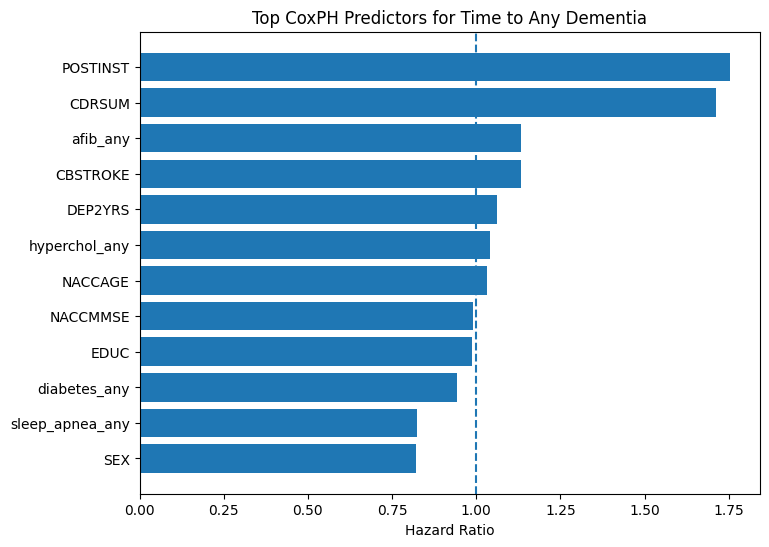

In [196]:
import matplotlib.pyplot as plt

top_hr = hr_table.sort_values("p_value").head(12).sort_values("hazard_ratio")

plt.figure(figsize=(8,6))
plt.barh(top_hr.index.astype(str), top_hr["hazard_ratio"])
plt.axvline(1.0, linestyle="--")
plt.xlabel("Hazard Ratio")
plt.title("Top CoxPH Predictors for Time to Any Dementia")
plt.show()

In [197]:
cox.check_assumptions(cox_df_model, p_value_threshold=0.05, show_plots=False)

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'NACCAGE' failed the non-proportional test: p-value is <5e-05.

   Advice 1: the functional form of the variable 'NACCAGE' might be incorrect. That is, there may be
non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'NACCAGE' using pd.cut, and then specify it in
`strata=['NACCAGE', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


2. Variable 'SEX' failed the non-proportional test: p-value is 0.0013.

   Advice: with so few unique values (only 2), you can include `strata=['SEX', ...]` in the call in
`.fit`. See documentation in link [E] below.

3. Variable 'EDUC' failed the non-proportional test: p-value is 0.0527.

   Advice 1: the functional form of the variable 'EDUC' might be in

[]

In [198]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from lifelines import CoxPHFitter, KaplanMeierFitter, AalenJohansenFitter
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [ ]:
# master modeling dataframe

# Starting from cox_df (already merged with baseline features)
model_df = cox_df.copy()

# Binary event
model_df["event_any_dementia"] = (model_df["event_type"] != "Censored").astype(int)

# Keeping only rows with valid time
model_df = model_df[
    model_df["time_to_event"].notna() &
    (model_df["time_to_event"] > 0)
].copy()

print("model_df shape:", model_df.shape)
print(model_df["event_type"].value_counts(dropna=False))

model_df shape: (27052, 24)
event_type
Censored    22201
AD           4218
PD_LBD        374
Vascular      259
Name: count, dtype: int64


1) COMPETING RISKS
Cell 26 — Numeric code for competing events

In [ ]:
# competing risk event coding:
# 0 = censored
# 1 = AD
# 2 = PD_LBD
# 3 = Vascular

event_code_map = {
    "Censored": 0,
    "AD": 1,
    "PD_LBD": 2,
    "Vascular": 3
}

cr_df = model_df[model_df["event_type"].isin(event_code_map.keys())].copy()
cr_df["event_code"] = cr_df["event_type"].map(event_code_map).astype(int)

print(cr_df["event_type"].value_counts())
print(cr_df["event_code"].value_counts())

event_type
Censored    22201
AD           4218
PD_LBD        374
Vascular      259
Name: count, dtype: int64
event_code
0    22201
1     4218
2      374
3      259
Name: count, dtype: int64


Cell 27 — Cumulative incidence curves (Aalen-Johansen)


c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(


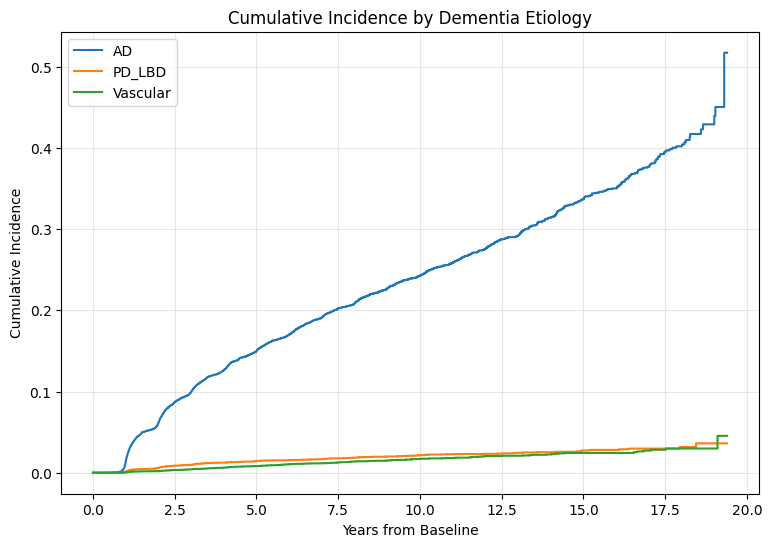

In [ ]:
# cumulative incidence curves for competing risks

plt.figure(figsize=(9, 6))

for event_name, event_code in [("AD", 1), ("PD_LBD", 2), ("Vascular", 3)]:
    ajf = AalenJohansenFitter()
    ajf.fit(
        durations=cr_df["time_to_event"],
        event_observed=cr_df["event_code"],
        event_of_interest=event_code
    )
    ajf.plot(ci_show=False)

plt.title("Cumulative Incidence by Dementia Etiology")
plt.xlabel("Years from Baseline")
plt.ylabel("Cumulative Incidence")
plt.grid(True, alpha=0.3)
plt.legend(["AD", "PD_LBD", "Vascular"])
plt.show()

# Milestone cumulative incidence table

In [234]:
# =========================================================
# Competing-risk cumulative incidence milestone table
# Add after your current Aalen-Johansen plot cell
# =========================================================

milestone_years = [5, 10, 15]
event_map = {"AD": 1, "PD_LBD": 2, "Vascular": 3}

aj_tables = {}

for event_name, event_code in event_map.items():
    ajf = AalenJohansenFitter()
    ajf.fit(
        durations=cr_df["time_to_event"],
        event_observed=cr_df["event_code"],
        event_of_interest=event_code
    )

    cif_vals = []
    for yr in milestone_years:
        # nearest available timepoint
        idx = np.argmin(np.abs(ajf.cumulative_density_.index.values - yr))
        cif_val = float(ajf.cumulative_density_.iloc[idx, 0])
        cif_vals.append(cif_val)

    aj_tables[event_name] = cif_vals

cif_milestone_table = pd.DataFrame(aj_tables, index=milestone_years)
cif_milestone_table.index.name = "Years"
display(cif_milestone_table)

c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(


,AD,PD_LBD,Vascular
Years,,,
5,0.149808,0.014208,0.008155
10,0.242582,0.021564,0.017068
15,0.336779,0.027464,0.024371


2) cause-specific cox model
Cell 28 — Helper to fit cause-specific Cox

In [ ]:
# cause-specific cox helper

def fit_cause_specific_cox(df, event_name, features, penalizer=0.1):
    tmp = df.copy()
    tmp["event_cs"] = (tmp["event_type"] == event_name).astype(int)

    use_cols = ["time_to_event", "event_cs"] + [c for c in features if c in tmp.columns]
    tmp = tmp[use_cols].copy()

    for col in tmp.columns:
        if col in ["time_to_event", "event_cs"]:
            continue
        if pd.api.types.is_numeric_dtype(tmp[col]):
            tmp[col] = tmp[col].fillna(tmp[col].median())
        else:
            mode_vals = tmp[col].mode()
            if len(mode_vals) > 0:
                tmp[col] = tmp[col].fillna(mode_vals.iloc[0])

    # one-hot encoding categorical
    cat_cols = [c for c in tmp.columns if c not in ["time_to_event", "event_cs"] and not pd.api.types.is_numeric_dtype(tmp[c])]
    if len(cat_cols) > 0:
        tmp = pd.get_dummies(tmp, columns=cat_cols, drop_first=True)

    cph = CoxPHFitter(penalizer=penalizer)
    cph.fit(tmp, duration_col="time_to_event", event_col="event_cs")
    return cph, tmp

Cell 29 — Run cause-specific Cox for AD / PD_LBD / Vascular

In [ ]:
# cause-specific cox models

# cause_features = [
#     "NACCAGE",
#     "SEX",
#     "EDUC",
#     "NACCMMSE",
#     "CDRSUM",
#     "DIABETES",
#     "HYPERTEN",
#     "HYPERCHO",
#     "CBSTROKE",
#     "CVAFIB",
#     "DEP2YRS"
# ]

cause_features = [
    "NACCAGE",
    "SEX",
    "EDUC",
    "NACCMMSE",
    "CDRSUM",
    "DEP2YRS",
    "diabetes_any",
    "htn_any",
    "hyperchol_any",
    "afib_any",
    "sleep_apnea_any",
    "CBSTROKE",
    "CVDSIGNS",
    "POSTINST"
]

cause_models = {}
cause_dfs = {}

for outcome in ["AD", "PD_LBD", "Vascular"]:
    cph, tmp_df = fit_cause_specific_cox(model_df, outcome, cause_features, penalizer=0.1)
    cause_models[outcome] = cph
    cause_dfs[outcome] = tmp_df

    print("\n" + "=" * 70)
    print(f"CAUSE-SPECIFIC COX FOR: {outcome}")
    print("=" * 70)
    display(
        cph.summary[["coef", "exp(coef)", "se(coef)", "p"]]
        .sort_values("p")
        .head(15)
    )


CAUSE-SPECIFIC COX FOR: AD


,coef,exp(coef),se(coef),p
covariate,,,,
CDRSUM,0.528021,1.695573,0.007671,0.000000e+00
NACCAGE,0.031697,1.032204,0.001300,2.239368e-131
NACCMMSE,-0.009202,0.990840,0.001642,2.073129e-08
sleep_apnea_any,-0.203475,0.815891,0.036993,3.791161e-08
SEX,-0.129512,0.878524,0.024568,1.352863e-07
EDUC,-0.014095,0.986004,0.003929,3.336187e-04
DEP2YRS,0.045229,1.046267,0.012843,4.288158e-04
diabetes_any,-0.063723,0.938265,0.036928,8.442312e-02
hyperchol_any,0.032547,1.033083,0.024507,1.841478e-01



CAUSE-SPECIFIC COX FOR: PD_LBD


,coef,exp(coef),se(coef),p
covariate,,,,
POSTINST,1.524776,4.594115,0.126272,1.425550e-33
CDRSUM,0.176801,1.193393,0.018918,9.144696e-21
SEX,-0.189822,0.827106,0.036728,2.361752e-07
DEP2YRS,0.033104,1.033658,0.019709,9.303690e-02
NACCMMSE,-0.002840,0.997164,0.002277,2.122086e-01
htn_any,-0.038388,0.962340,0.036107,2.877064e-01
afib_any,0.082131,1.085598,0.077656,2.902297e-01
NACCAGE,0.001758,1.001759,0.001811,3.317509e-01
diabetes_any,-0.046073,0.954973,0.054415,3.971645e-01



CAUSE-SPECIFIC COX FOR: Vascular


,coef,exp(coef),se(coef),p
covariate,,,,
CBSTROKE,0.334360,1.397046,0.056867,4.111001e-09
CDRSUM,0.078553,1.081720,0.019585,6.050592e-05
NACCAGE,0.007114,1.007139,0.001848,1.186881e-04
CVDSIGNS,0.529218,1.697604,0.162434,1.121792e-03
htn_any,0.090447,1.094663,0.036774,1.391308e-02
afib_any,0.157257,1.170296,0.078999,4.652268e-02
diabetes_any,0.093989,1.098548,0.055110,8.810408e-02
DEP2YRS,0.025734,1.026068,0.020198,2.026427e-01
hyperchol_any,0.045149,1.046184,0.036788,2.197159e-01


Cell 30 — Plot top hazard ratios for each cause-specific model

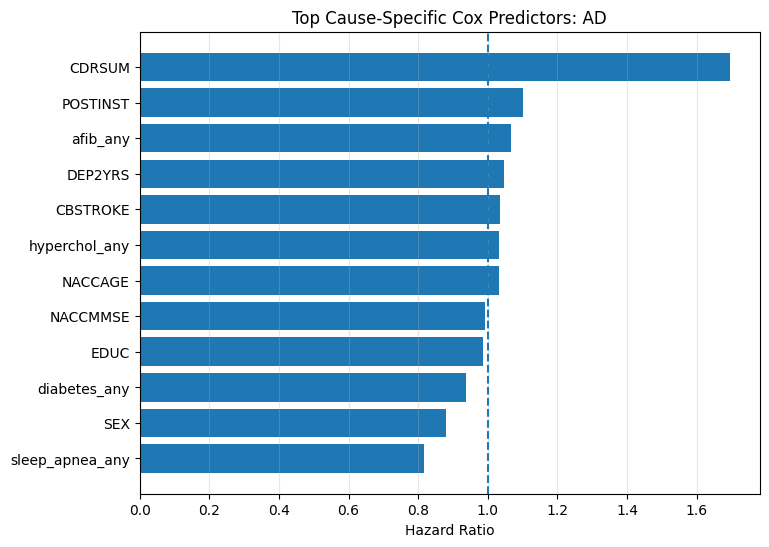

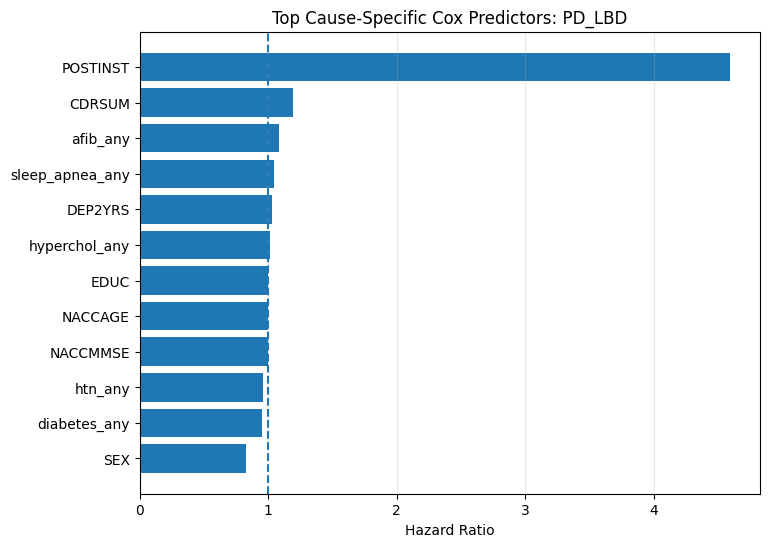

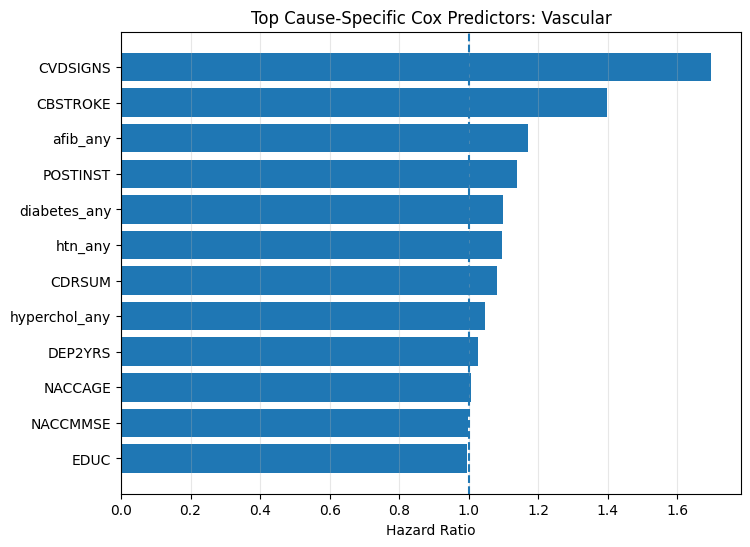

In [204]:
# =========================================================
# TOP HR PLOTS FOR EACH ETIOLOGY
# =========================================================

for outcome, cph in cause_models.items():
    hr_table = cph.summary[["exp(coef)", "p"]].copy()
    hr_table = hr_table.rename(columns={"exp(coef)": "hazard_ratio", "p": "p_value"})
    hr_table = hr_table.sort_values("p_value").head(12).sort_values("hazard_ratio")

    plt.figure(figsize=(8, 6))
    plt.barh(hr_table.index.astype(str), hr_table["hazard_ratio"])
    plt.axvline(1.0, linestyle="--")
    plt.xlabel("Hazard Ratio")
    plt.title(f"Top Cause-Specific Cox Predictors: {outcome}")
    plt.grid(True, axis="x", alpha=0.3)
    plt.show()

# CDRSUM vs no-CDRSUM

Tests whether model is just driven by baseline cognitive severity.

In [242]:
# =========================================================
# CDRSUM vs no-CDRSUM sensitivity analysis
# Add after cause-specific Cox models
# =========================================================

def prep_for_cox(df, features, duration_col="time_to_event", event_col="event_flag"):
    tmp = df[[duration_col, event_col] + [c for c in features if c in df.columns]].copy()

    for col in tmp.columns:
        if col in [duration_col, event_col]:
            continue
        if pd.api.types.is_numeric_dtype(tmp[col]):
            tmp[col] = pd.to_numeric(tmp[col], errors="coerce")
            tmp[col] = tmp[col].fillna(tmp[col].median())
        else:
            mode_vals = tmp[col].mode()
            if len(mode_vals) > 0:
                tmp[col] = tmp[col].fillna(mode_vals.iloc[0])

    cat_cols = [
        c for c in tmp.columns
        if c not in [duration_col, event_col] and not pd.api.types.is_numeric_dtype(tmp[c])
    ]
    if len(cat_cols) > 0:
        tmp = pd.get_dummies(tmp, columns=cat_cols, drop_first=True)

    return tmp


# base_features_with_cdr = [
#     "NACCAGE", "SEX", "EDUC", "NACCMMSE", "CDRSUM", "DEP2YRS",
#     "CBSTROKE", "CVDSIGNS", "POSTINST",
#     "DIABETES", "HYPERTEN", "HYPERCHO", "CVAFIB", "SLEEPAP",
#     "vascular_burden_index"
# ]

base_features_with_cdr = [
    "NACCAGE",
    "SEX",
    "EDUC",
    "NACCMMSE",
    "CDRSUM",
    "DEP2YRS",
    "diabetes_any",
    "htn_any",
    "hyperchol_any",
    "afib_any",
    "sleep_apnea_any",
    "CBSTROKE",
    "CVDSIGNS",
    "POSTINST"
]

base_features_no_cdr = [f for f in base_features_with_cdr if f != "CDRSUM"]


def fit_compare_model(df, event_name=None):
    tmp = df.copy()

    if event_name is None:
        tmp["event_flag"] = tmp["event_any_dementia"].astype(int)
        model_label = "AnyDementia"
    else:
        tmp["event_flag"] = (tmp["event_type"] == event_name).astype(int)
        model_label = event_name

    # with CDRSUM
    df_with = prep_for_cox(tmp, base_features_with_cdr, event_col="event_flag")
    cph_with = CoxPHFitter(penalizer=0.1)
    cph_with.fit(df_with, duration_col="time_to_event", event_col="event_flag")

    # without CDRSUM
    df_no = prep_for_cox(tmp, base_features_no_cdr, event_col="event_flag")
    cph_no = CoxPHFitter(penalizer=0.1)
    cph_no.fit(df_no, duration_col="time_to_event", event_col="event_flag")

    return {
        "label": model_label,
        "with_cdr": cph_with,
        "without_cdr": cph_no,
        "df_with": df_with,
        "df_no": df_no
    }


sensitivity_results = {}
for outcome in [None, "AD", "PD_LBD", "Vascular"]:
    res = fit_compare_model(model_df, outcome)
    sensitivity_results[res["label"]] = res

summary_rows = []
for label, res in sensitivity_results.items():
    summary_rows.append({
        "model": label,
        "concordance_with_cdr": res["with_cdr"].concordance_index_,
        "concordance_without_cdr": res["without_cdr"].concordance_index_,
        "partial_AIC_with_cdr": res["with_cdr"].AIC_partial_,
        "partial_AIC_without_cdr": res["without_cdr"].AIC_partial_
    })

sensitivity_summary = pd.DataFrame(summary_rows)
display(sensitivity_summary)

,model,concordance_with_cdr,concordance_without_cdr,partial_AIC_with_cdr,partial_AIC_without_cdr
0,AnyDementia,0.850408,0.677329,87050.222412,90233.895218
1,AD,0.850334,0.668283,75995.064979,78692.770451
2,PD_LBD,0.911833,0.809859,6905.145154,6989.153816
3,Vascular,0.876194,0.847556,4699.621595,4713.660509


# Cross-etiology heatmap

In [243]:
# =========================================================
# Cross-etiology factor comparison heatmap
# Add after the sensitivity analysis
# =========================================================

# Choose the cause-specific models WITH CDRSUM for comparison
heatmap_models = {
    "AD": sensitivity_results["AD"]["with_cdr"],
    "PD_LBD": sensitivity_results["PD_LBD"]["with_cdr"],
    "Vascular": sensitivity_results["Vascular"]["with_cdr"]
}

# predictors to display
predictors_of_interest = [
    "NACCAGE",
    "SEX",
    "EDUC",
    "NACCMMSE",
    "CDRSUM",
    "DEP2YRS",
    "diabetes_any",
    "htn_any",
    "hyperchol_any",
    "afib_any",
    "sleep_apnea_any",
    "CBSTROKE",
    "CVDSIGNS",
    "POSTINST"
]


heatmap_data = pd.DataFrame(index=predictors_of_interest)

for label, model in heatmap_models.items():
    vals = []
    for pred in predictors_of_interest:
        if pred in model.summary.index:
            vals.append(model.summary.loc[pred, "coef"])   # log(HR)
        else:
            vals.append(np.nan)
    heatmap_data[label] = vals

display(heatmap_data)

,AD,PD_LBD,Vascular
NACCAGE,0.031697,0.001758,0.007114
SEX,-0.129512,-0.189822,-0.030735
EDUC,-0.014095,0.002365,-0.005273
NACCMMSE,-0.009202,-0.002840,-0.002207
CDRSUM,0.528021,0.176801,0.078553
DEP2YRS,0.045229,0.033104,0.025734
diabetes_any,-0.063723,-0.046073,0.093989
htn_any,-0.009281,-0.038388,0.090447
hyperchol_any,0.032547,0.013680,0.045149
afib_any,0.065249,0.082131,0.157257


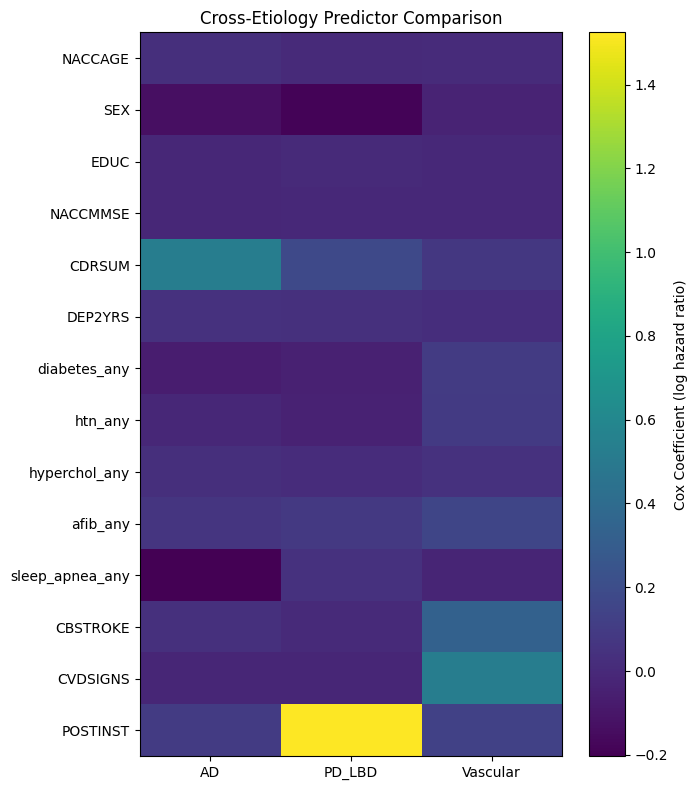

In [244]:
plt.figure(figsize=(7, 8))

plot_data = heatmap_data.copy()

im = plt.imshow(plot_data.values, aspect="auto")
plt.colorbar(im, label="Cox Coefficient (log hazard ratio)")

plt.xticks(range(len(plot_data.columns)), plot_data.columns)
plt.yticks(range(len(plot_data.index)), plot_data.index)
plt.title("Cross-Etiology Predictor Comparison")
plt.tight_layout()
plt.show()

3) VASCULAR BURDEN INDEX

This is one of the best additions for your notebook.

Cell 31 — Build vascular burden index

In [205]:
# =========================================================
# VASCULAR BURDEN INDEX
# =========================================================

# vascular_candidates = [
#     "CBSTROKE",   # stroke
#     "HYPERTEN",   # HTN
#     "DIABETES",   # diabetes
#     "HYPERCHO",   # hypercholesterolemia
#     "CVAFIB",     # afib
#     "CVCHF",      # CHF if present
#     "CBTIA",      # TIA if present
#     "BPSYS",      # systolic BP if present
#     "BPDIAS",     # diastolic BP if present
#     "SMOKYRS",    # smoking years if present
#     "PACKSPER"    # smoking intensity if present
# ]


# smoking exposure index
if "SMOKYRS" in model_df.columns and "PACKSPER" in model_df.columns:
    model_df["smoking_exposure"] = (
        model_df["SMOKYRS"].fillna(0) *
        model_df["PACKSPER"].fillna(0)
    )

vascular_candidates = [
    "CBSTROKE",
    "CBTIA",
    "diabetes_any",
    "htn_any",
    "hyperchol_any",
    "afib_any",
    "sleep_apnea_any",
    "CVDSIGNS",
    "POSTINST",
    "smoking_exposure"
]

vascular_features = [c for c in vascular_candidates if c in model_df.columns]
print("vascular_features:", vascular_features)

vascular_features = [c for c in vascular_candidates if c in model_df.columns]
print("vascular_features:", vascular_features)

# Define target: vascular dementia vs everyone else
vbi_df = model_df.copy()
vbi_df["vascular_target"] = (vbi_df["event_type"] == "Vascular").astype(int)

X_vbi = vbi_df[vascular_features].copy()
y_vbi = vbi_df["vascular_target"].copy()

# Fill missing
for col in X_vbi.columns:
    if pd.api.types.is_numeric_dtype(X_vbi[col]):
        X_vbi[col] = X_vbi[col].fillna(X_vbi[col].median())
    else:
        mode_vals = X_vbi[col].mode()
        if len(mode_vals) > 0:
            X_vbi[col] = X_vbi[col].fillna(mode_vals.iloc[0])

# One-hot if needed
cat_cols = [c for c in X_vbi.columns if not pd.api.types.is_numeric_dtype(X_vbi[c])]
if len(cat_cols) > 0:
    X_vbi = pd.get_dummies(X_vbi, columns=cat_cols, drop_first=True)

vbi_model = LogisticRegression(
    class_weight="balanced",
    max_iter=5000,
    random_state=RANDOM_STATE
)
vbi_model.fit(X_vbi, y_vbi)

# Probability = vascular burden index
vbi_df["vascular_burden_index"] = vbi_model.predict_proba(X_vbi)[:, 1]

print(vbi_df["vascular_burden_index"].describe())

vascular_features: ['CBSTROKE', 'diabetes_any', 'htn_any', 'hyperchol_any', 'afib_any', 'sleep_apnea_any', 'CVDSIGNS', 'POSTINST']
vascular_features: ['CBSTROKE', 'diabetes_any', 'htn_any', 'hyperchol_any', 'afib_any', 'sleep_apnea_any', 'CVDSIGNS', 'POSTINST']
count    27052.000000
mean         0.404737
std          0.160430
min          0.205985
25%          0.252242
50%          0.420089
75%          0.485054
max          0.996703
Name: vascular_burden_index, dtype: float64


Cell 32 — Inspect vascular burden weights

In [206]:
# =========================================================
# INSPECT VASCULAR BURDEN MODEL WEIGHTS
# =========================================================

vbi_coef = pd.DataFrame({
    "feature": X_vbi.columns,
    "coef": vbi_model.coef_[0]
}).sort_values("coef", ascending=False)

display(vbi_coef)

,feature,coef
6,CVDSIGNS,2.025429
0,CBSTROKE,1.179144
7,POSTINST,0.995636
4,afib_any,0.873683
2,htn_any,0.839607
1,diabetes_any,0.513776
3,hyperchol_any,0.187284
5,sleep_apnea_any,-0.262608


Cell 33 — Merge vascular burden into survival modeling

In [207]:
# =========================================================
# ADD VBI INTO SURVIVAL MODEL
# =========================================================

model_df = model_df.merge(
    vbi_df[["NACCID", "vascular_burden_index"]],
    on="NACCID",
    how="left"
)

# If duplicate merge created repeated columns, fix safely
if "vascular_burden_index_x" in model_df.columns:
    model_df["vascular_burden_index"] = model_df["vascular_burden_index_x"]
    drop_cols = [c for c in ["vascular_burden_index_x", "vascular_burden_index_y"] if c in model_df.columns]
    model_df = model_df.drop(columns=drop_cols)

print(model_df[["NACCID", "vascular_burden_index"]].head())

       NACCID  vascular_burden_index
0  NACC000011               0.252242
1  NACC000034               0.485054
2  NACC000067               0.252242
3  NACC000138               0.252242
4  NACC000144               0.692936


Cell 34 — Refit any-dementia Cox with vascular burden index

In [208]:
# =========================================================
# ANY-DEMENTIA COX + VASCULAR BURDEN INDEX
# =========================================================

cox_features_plus_vbi = [
    "NACCAGE",
    "SEX",
    "EDUC",
    "NACCMMSE",
    "CDRSUM",
    "DIABETES",
    "HYPERTEN",
    "HYPERCHO",
    "CBSTROKE",
    "CVAFIB",
    "DEP2YRS",
    "vascular_burden_index"
]

cox_vbi_df = model_df[["time_to_event", "event_any_dementia"] + [c for c in cox_features_plus_vbi if c in model_df.columns]].copy()

for col in cox_vbi_df.columns:
    if col in ["time_to_event", "event_any_dementia"]:
        continue
    if pd.api.types.is_numeric_dtype(cox_vbi_df[col]):
        cox_vbi_df[col] = cox_vbi_df[col].fillna(cox_vbi_df[col].median())
    else:
        mode_vals = cox_vbi_df[col].mode()
        if len(mode_vals) > 0:
            cox_vbi_df[col] = cox_vbi_df[col].fillna(mode_vals.iloc[0])

cat_cols = [c for c in cox_vbi_df.columns if c not in ["time_to_event", "event_any_dementia"] and not pd.api.types.is_numeric_dtype(cox_vbi_df[c])]
if len(cat_cols) > 0:
    cox_vbi_df = pd.get_dummies(cox_vbi_df, columns=cat_cols, drop_first=True)

cox_vbi = CoxPHFitter(penalizer=0.1)
cox_vbi.fit(cox_vbi_df, duration_col="time_to_event", event_col="event_any_dementia")

display(
    cox_vbi.summary[["coef", "exp(coef)", "se(coef)", "p"]]
    .sort_values("p")
    .head(20)
)

,coef,exp(coef),se(coef),p
covariate,,,,
CDRSUM,0.531631,1.701706,0.006945,0.000000e+00
NACCAGE,0.033009,1.033560,0.001249,7.450950e-154
SEX,-0.190850,0.826257,0.023384,3.311299e-16
NACCMMSE,-0.009985,0.990065,0.001597,4.074452e-10
DEP2YRS,0.058082,1.059802,0.011851,9.537847e-07
vascular_burden_index,0.262671,1.300399,0.075472,5.007214e-04
EDUC,-0.012050,0.988022,0.003740,1.273418e-03
CBSTROKE,0.080902,1.084264,0.034724,1.981551e-02


Cell 35 — Survival curves stratified by vascular burden tertiles

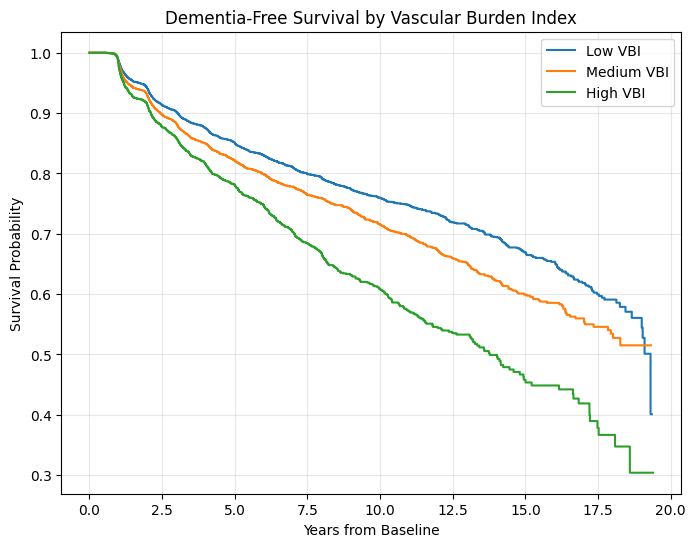

In [209]:
# =========================================================
# KAPLAN-MEIER BY VASCULAR BURDEN TERTILE
# =========================================================

km_vbi_df = model_df[["time_to_event", "event_any_dementia", "vascular_burden_index"]].dropna().copy()
km_vbi_df["vbi_group"] = pd.qcut(
    km_vbi_df["vascular_burden_index"],
    q=3,
    labels=["Low VBI", "Medium VBI", "High VBI"]
)

plt.figure(figsize=(8, 6))
kmf = KaplanMeierFitter()

for grp in ["Low VBI", "Medium VBI", "High VBI"]:
    tmp = km_vbi_df[km_vbi_df["vbi_group"] == grp]
    kmf.fit(
        durations=tmp["time_to_event"],
        event_observed=tmp["event_any_dementia"],
        label=grp
    )
    kmf.plot(ci_show=False)

plt.title("Dementia-Free Survival by Vascular Burden Index")
plt.xlabel("Years from Baseline")
plt.ylabel("Survival Probability")
plt.grid(True, alpha=0.3)
plt.show()

# Stratified competing-risk plot

c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(


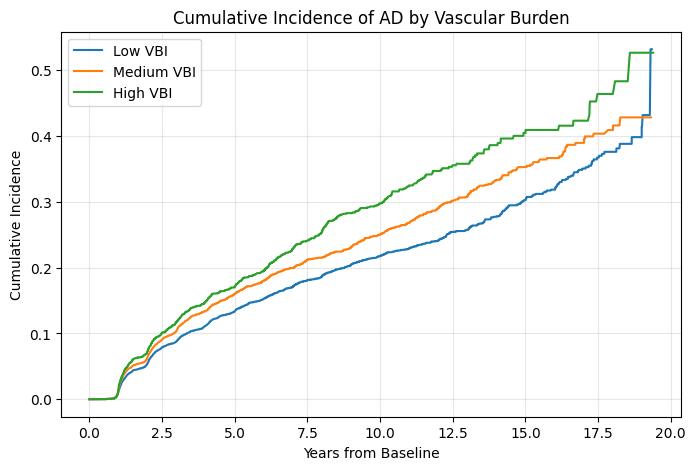

c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(


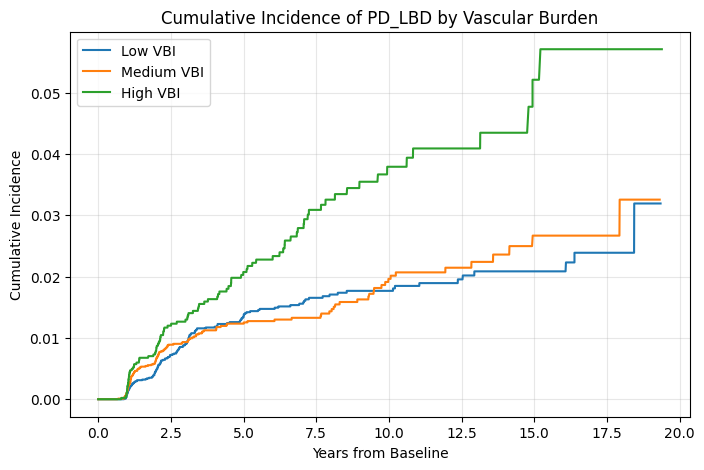

c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(


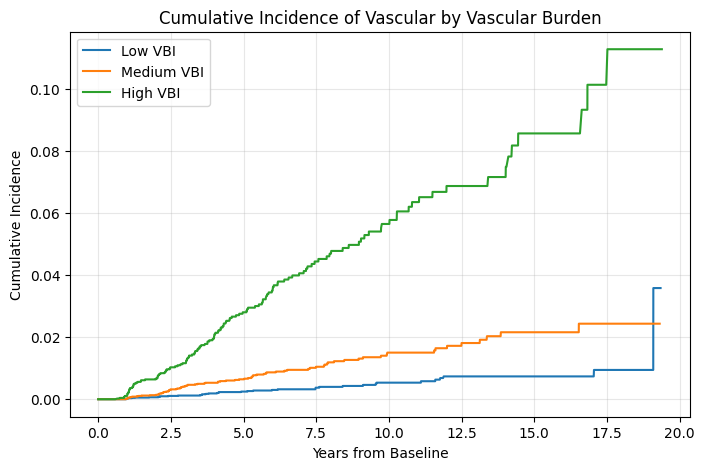

In [239]:
# =========================================================
# Stratified competing-risk cumulative incidence by VBI tertile
# Add after the VBI section and after cr_df exists
# =========================================================

# Merge VBI into competing-risk dataframe if needed
if "vascular_burden_index" not in cr_df.columns:
    cr_df = cr_df.merge(
        model_df[["NACCID", "vascular_burden_index"]].drop_duplicates(),
        on="NACCID",
        how="left"
    )

cr_df["vbi_group"] = pd.qcut(
    cr_df["vascular_burden_index"],
    q=3,
    labels=["Low VBI", "Medium VBI", "High VBI"]
)

event_map = {"AD": 1, "PD_LBD": 2, "Vascular": 3}

for event_name, event_code in event_map.items():
    plt.figure(figsize=(8, 5))

    for grp in ["Low VBI", "Medium VBI", "High VBI"]:
        tmp = cr_df[cr_df["vbi_group"] == grp].copy()

        ajf = AalenJohansenFitter()
        ajf.fit(
            durations=tmp["time_to_event"],
            event_observed=tmp["event_code"],
            event_of_interest=event_code
        )

        plt.plot(
            ajf.cumulative_density_.index,
            ajf.cumulative_density_.iloc[:, 0],
            label=grp
        )

    plt.title(f"Cumulative Incidence of {event_name} by Vascular Burden")
    plt.xlabel("Years from Baseline")
    plt.ylabel("Cumulative Incidence")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

In [240]:
milestone_years = [5, 10, 15]
rows = []

for event_name, event_code in event_map.items():
    for grp in ["Low VBI", "Medium VBI", "High VBI"]:
        tmp = cr_df[cr_df["vbi_group"] == grp].copy()

        ajf = AalenJohansenFitter()
        ajf.fit(
            durations=tmp["time_to_event"],
            event_observed=tmp["event_code"],
            event_of_interest=event_code
        )

        vals = {}
        for yr in milestone_years:
            idx = np.argmin(np.abs(ajf.cumulative_density_.index.values - yr))
            vals[f"{yr}y"] = float(ajf.cumulative_density_.iloc[idx, 0])

        rows.append({
            "event": event_name,
            "vbi_group": grp,
            **vals
        })

cif_vbi_table = pd.DataFrame(rows)
display(cif_vbi_table)

c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is randomly jittered.
  warnings.warn(
c:\Python314\Lib\site-packages\lifelines\fitters\aalen_johansen_fitter.py:112: Warning: Tied event times were detected. The Aalen-Johansen estimator cannot handle tied event times.
                To resolve ties, data is rand

,event,vbi_group,5y,10y,15y
0,AD,Low VBI,0.133596,0.217799,0.302950
1,AD,Medium VBI,0.160140,0.250414,0.352747
2,AD,High VBI,0.170709,0.297870,0.409013
3,PD_LBD,Low VBI,0.013375,0.017673,0.020854
4,PD_LBD,Medium VBI,0.012325,0.019626,0.026681
5,PD_LBD,High VBI,0.020747,0.037915,0.052064
6,Vascular,Low VBI,0.002460,0.005333,0.007349
7,Vascular,Medium VBI,0.006412,0.015005,0.021565
8,Vascular,High VBI,0.027993,0.056429,0.085581


In [ ]:
milestone_years = [5, 10, 15]
rows = []

for event_name, event_code in event_map.items():
    for grp in ["Low VBI", "Medium VBI", "High VBI"]:
        tmp = cr_df[cr_df["vbi_group"] == grp].copy()

        ajf = AalenJohansenFitter()
        ajf.fit(
            durations=tmp["time_to_event"],
            event_observed=tmp["event_code"],
            event_of_interest=event_code
        )

        vals = {}
        for yr in milestone_years:
            idx = np.argmin(np.abs(ajf.cumulative_density_.index.values - yr))
            vals[f"{yr}y"] = float(ajf.cumulative_density_.iloc[idx, 0])

        rows.append({
            "event": event_name,
            "vbi_group": grp,
            **vals
        })

cif_vbi_table = pd.DataFrame(rows)
display(cif_vbi_table)

4) BOOTSTRAP UNCERTAINTY-AWARE SURVIVAL PREDICTION
Cell 36 — Bootstrap Cox ensemble

This estimates prediction uncertainty.

In [210]:
# =========================================================
# BOOTSTRAP ENSEMBLE FOR UNCERTAINTY  --- FIXED
# =========================================================

N_BOOT = 30
PRED_HORIZON_YEARS = 5.0

boot_features = [
    "NACCAGE",
    "SEX",
    "EDUC",
    "NACCMMSE",
    "CDRSUM",
    "DIABETES",
    "HYPERTEN",
    "HYPERCHO",
    "CBSTROKE",
    "CVAFIB",
    "DEP2YRS",
    "vascular_burden_index"
]

# Keep NACCID only for tracking, not for model fitting
boot_df = model_df[["NACCID", "time_to_event", "event_any_dementia"] + [c for c in boot_features if c in model_df.columns]].copy()

# Fill missing values
for col in boot_df.columns:
    if col in ["NACCID", "time_to_event", "event_any_dementia"]:
        continue
    if pd.api.types.is_numeric_dtype(boot_df[col]):
        boot_df[col] = boot_df[col].fillna(boot_df[col].median())
    else:
        mode_vals = boot_df[col].mode()
        if len(mode_vals) > 0:
            boot_df[col] = boot_df[col].fillna(mode_vals.iloc[0])

# One-hot encode categorical columns
cat_cols = [
    c for c in boot_df.columns
    if c not in ["NACCID", "time_to_event", "event_any_dementia"]
    and not pd.api.types.is_numeric_dtype(boot_df[c])
]
if len(cat_cols) > 0:
    boot_df = pd.get_dummies(boot_df, columns=cat_cols, drop_first=True)

# Columns actually used in Cox model
fit_cols = [c for c in boot_df.columns if c != "NACCID"]

# Predictor columns only
boot_feature_cols = [
    c for c in fit_cols
    if c not in ["time_to_event", "event_any_dementia"]
]

risk_preds = []

for b in range(N_BOOT):
    sample_idx = np.random.choice(len(boot_df), size=len(boot_df), replace=True)

    # sample rows, but only pass numeric fit columns to Cox
    boot_sample = boot_df.iloc[sample_idx][fit_cols].copy()

    cph_b = CoxPHFitter(penalizer=0.1)
    cph_b.fit(
        boot_sample,
        duration_col="time_to_event",
        event_col="event_any_dementia"
    )

    surv_funcs = cph_b.predict_survival_function(
        boot_df[boot_feature_cols],
        times=[PRED_HORIZON_YEARS]
    )

    risk_5y = 1.0 - surv_funcs.T.iloc[:, 0].values
    risk_preds.append(risk_5y)

risk_preds = np.vstack(risk_preds)

print("risk_preds shape:", risk_preds.shape)
print("n patients:", len(boot_df))
print("n feature cols:", len(boot_feature_cols))

risk_preds shape: (30, 27052)
n patients: 27052
n feature cols: 8


Cell 37 — Compute uncertainty + confidence

In [211]:
# =========================================================
# UNCERTAINTY / CONFIDENCE SCORES
# =========================================================

uncertainty_df = boot_df[["NACCID", "time_to_event", "event_any_dementia"]].copy()
uncertainty_df["risk_5y_mean"] = risk_preds.mean(axis=0)
uncertainty_df["risk_5y_std"]  = risk_preds.std(axis=0)
uncertainty_df["risk_5y_p10"]  = np.percentile(risk_preds, 10, axis=0)
uncertainty_df["risk_5y_p90"]  = np.percentile(risk_preds, 90, axis=0)

# simple confidence score
max_std = uncertainty_df["risk_5y_std"].max()
uncertainty_df["confidence_score"] = 1 - (uncertainty_df["risk_5y_std"] / max_std)
uncertainty_df["confidence_score"] = uncertainty_df["confidence_score"].clip(0, 1)

display(uncertainty_df.head())
display(uncertainty_df.describe())

,NACCID,time_to_event,event_any_dementia,risk_5y_mean,risk_5y_std,risk_5y_p10,risk_5y_p90,confidence_score
0,NACC000011,3.296372,0,0.099550,0.002241,0.096605,0.102653,0.945841
1,NACC000034,5.848049,1,0.180711,0.003277,0.176399,0.185452,0.920830
2,NACC000067,2.088980,0,0.116137,0.003540,0.111771,0.120699,0.914459
3,NACC000138,1.043121,0,0.060103,0.001786,0.057864,0.062601,0.956852
4,NACC000144,8.487337,0,0.177213,0.004935,0.170769,0.183536,0.880754


,time_to_event,event_any_dementia,risk_5y_mean,risk_5y_std,risk_5y_p10,risk_5y_p90,confidence_score
count,27052.000000,27052.000000,27052.000000,27052.000000,27052.000000,27052.000000,27052.000000
mean,5.117712,0.179321,0.180338,0.005337,0.173660,0.186945,0.871043
std,4.214639,0.383628,0.135754,0.004350,0.130865,0.140017,0.105107
min,0.109514,0.000000,0.013133,0.000000,0.011129,0.014671,0.000000
25%,1.938398,0.000000,0.102004,0.002732,0.098404,0.105741,0.857031
50%,3.786448,0.000000,0.137382,0.003872,0.132560,0.142446,0.906450
75%,7.124572,0.000000,0.202158,0.005917,0.194971,0.209721,0.933981
max,19.392197,1.000000,1.000000,0.041387,1.000000,1.000000,1.000000


Cell 38 — Scatter plot: risk vs uncertainty

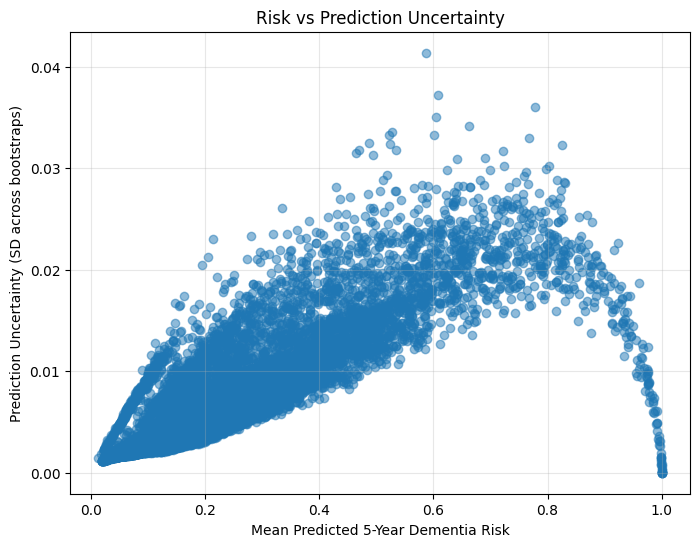

In [212]:
# =========================================================
# RISK VS UNCERTAINTY PLOT
# =========================================================

plt.figure(figsize=(8, 6))
plt.scatter(
    uncertainty_df["risk_5y_mean"],
    uncertainty_df["risk_5y_std"],
    alpha=0.5
)
plt.xlabel("Mean Predicted 5-Year Dementia Risk")
plt.ylabel("Prediction Uncertainty (SD across bootstraps)")
plt.title("Risk vs Prediction Uncertainty")
plt.grid(True, alpha=0.3)
plt.show()

Cell 39 — Identify high-uncertainty cases

In [213]:
# =========================================================
# FLAG HIGH-UNCERTAINTY CASES
# =========================================================

uncert_thresh = uncertainty_df["risk_5y_std"].quantile(0.80)
uncertainty_df["high_uncertainty"] = (uncertainty_df["risk_5y_std"] >= uncert_thresh).astype(int)

print("High-uncertainty threshold:", uncert_thresh)
print(uncertainty_df["high_uncertainty"].value_counts())

display(
    uncertainty_df.sort_values("risk_5y_std", ascending=False).head(15)
)

High-uncertainty threshold: 0.006773130613926387
high_uncertainty
0    21641
1     5411
Name: count, dtype: int64


,NACCID,time_to_event,event_any_dementia,risk_5y_mean,risk_5y_std,risk_5y_p10,risk_5y_p90,confidence_score,high_uncertainty
13886,NACC513213,5.043121,0,0.587168,0.041387,0.537430,0.637543,0.000000,1
6746,NACC252469,0.977413,0,0.608622,0.037227,0.562226,0.652826,0.100518,1
25806,NACC954148,0.996578,0,0.778674,0.036075,0.750586,0.819323,0.128350,1
3363,NACC126236,6.483231,1,0.605117,0.035074,0.568642,0.654325,0.152548,1
4194,NACC156995,1.029432,1,0.662363,0.034182,0.617667,0.702230,0.174092,1
15166,NACC560554,5.385352,1,0.527459,0.033582,0.491763,0.565801,0.188582,1
3179,NACC118240,1.152635,0,0.521551,0.033320,0.480686,0.565076,0.194913,1
16735,NACC618336,1.034908,1,0.600779,0.033250,0.555016,0.638458,0.196607,1
24874,NACC916991,4.731006,1,0.767283,0.032961,0.737382,0.804079,0.203592,1
21770,NACC803559,1.322382,0,0.487290,0.032515,0.452941,0.522143,0.214359,1


5) UNCERTAIN-CASE PHENOTYPE ANALYSIS
Cell 40 — Merge uncertainty back to clinical variables

In [214]:
# =========================================================
# MERGE UNCERTAINTY BACK FOR PHENOTYPE ANALYSIS
# =========================================================

analysis_df = model_df.merge(
    uncertainty_df[["NACCID", "risk_5y_mean", "risk_5y_std", "confidence_score", "high_uncertainty"]],
    on="NACCID",
    how="left"
)

print(analysis_df.shape)

(27052, 29)


Cell 41 — Compare high- vs low-uncertainty groups

In [215]:
# =========================================================
# PHENOTYPE COMPARISON: HIGH VS LOW UNCERTAINTY
# =========================================================

compare_vars = [
    "NACCAGE",
    "EDUC",
    "NACCMMSE",
    "CDRSUM",
    "DIABETES",
    "HYPERTEN",
    "HYPERCHO",
    "CBSTROKE",
    "CVAFIB",
    "DEP2YRS",
    "vascular_burden_index"
]

rows = []
for col in compare_vars:
    if col not in analysis_df.columns:
        continue

    tmp0 = analysis_df.loc[analysis_df["high_uncertainty"] == 0, col]
    tmp1 = analysis_df.loc[analysis_df["high_uncertainty"] == 1, col]

    rows.append({
        "variable": col,
        "low_uncert_mean": pd.to_numeric(tmp0, errors="coerce").mean(),
        "high_uncert_mean": pd.to_numeric(tmp1, errors="coerce").mean(),
        "difference": pd.to_numeric(tmp1, errors="coerce").mean() - pd.to_numeric(tmp0, errors="coerce").mean()
    })

uncert_compare = pd.DataFrame(rows).sort_values("difference", ascending=False)
display(uncert_compare)

,variable,low_uncert_mean,high_uncert_mean,difference
0,NACCAGE,69.485283,76.325633,6.840350
3,CDRSUM,0.243589,1.783497,1.539908
2,NACCMMSE,29.451889,30.818157,1.366268
5,DEP2YRS,0.203965,0.678618,0.474653
4,CBSTROKE,0.007217,0.248700,0.241483
6,vascular_burden_index,0.387421,0.473990,0.086569
1,EDUC,16.052111,14.961553,-1.090558


Cell 42 — Event-type breakdown inside high-uncertainty cases

In [216]:
# =========================================================
# WHAT TYPES OF EVENTS APPEAR IN HIGH-UNCERTAINTY CASES?
# =========================================================

event_uncert_table = pd.crosstab(
    analysis_df["event_type"],
    analysis_df["high_uncertainty"],
    normalize="columns"
)

display(event_uncert_table)

high_uncertainty,0,1
event_type,,
AD,0.098748,0.384587
Censored,0.887944,0.551654
PD_LBD,0.007347,0.039734
Vascular,0.005961,0.024025


Using Cox model: cox_vbi


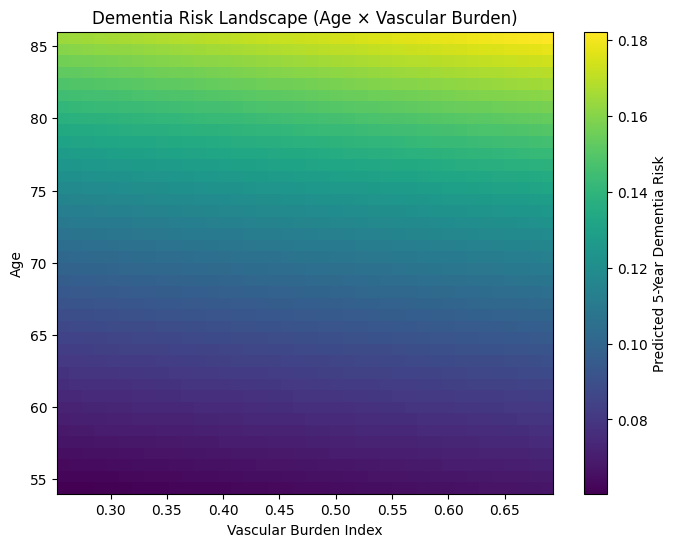

In [233]:
# =========================================================
# Dementia Risk Landscape: Age x Vascular Burden
# =========================================================

# Identify the Cox model with vascular burden
main_cph = None
for name in ["cox_vbi", "cph_vbi", "cox_ph", "cox_model"]:
    if name in globals():
        main_cph = globals()[name]
        print("Using Cox model:", name)
        break

if main_cph is None:
    raise ValueError("Could not find the Cox model with vascular_burden_index")

# Columns used by the Cox model
model_cols = list(main_cph.params_.index)

# Create a "typical patient" baseline profile
reference = {}
for col in model_cols:
    if col in analysis_df.columns:
        reference[col] = analysis_df[col].median()
    else:
        reference[col] = 0

# If sex exists, use most common value
if "SEX" in analysis_df.columns:
    reference["SEX"] = analysis_df["SEX"].mode()[0]

# Grid ranges
age_grid = np.linspace(
    analysis_df["NACCAGE"].quantile(0.05),
    analysis_df["NACCAGE"].quantile(0.95),
    40
)

vbi_grid = np.linspace(
    analysis_df["vascular_burden_index"].quantile(0.05),
    analysis_df["vascular_burden_index"].quantile(0.95),
    40
)

# Build prediction grid
grid_rows = []

for age in age_grid:
    for vbi in vbi_grid:
        row = reference.copy()
        if "NACCAGE" in row:
            row["NACCAGE"] = age
        if "vascular_burden_index" in row:
            row["vascular_burden_index"] = vbi
        grid_rows.append(row)

grid_df = pd.DataFrame(grid_rows)[model_cols]

# Ensure numeric
for col in grid_df.columns:
    grid_df[col] = pd.to_numeric(grid_df[col], errors="coerce").fillna(0)

# Predict 5-year risk
surv = main_cph.predict_survival_function(grid_df, times=[5.0])
risk_5y = 1 - surv.T.iloc[:, 0].values

risk_matrix = risk_5y.reshape(len(age_grid), len(vbi_grid))

plt.figure(figsize=(8,6))

im = plt.imshow(
    risk_matrix,
    aspect="auto",
    origin="lower",
    extent=[
        vbi_grid.min(),
        vbi_grid.max(),
        age_grid.min(),
        age_grid.max()
    ]
)

plt.colorbar(im, label="Predicted 5-Year Dementia Risk")

plt.xlabel("Vascular Burden Index")
plt.ylabel("Age")
plt.title("Dementia Risk Landscape (Age × Vascular Burden)")

plt.show()

6) OPTIONAL DISAGREEMENT ANALYSIS HOOK

This one needs classifier predictions from your classification notebook.

Expected columns:

NACCID

predicted_class

with values like:

AD

PD_LBD

Vascular

NoDementia_Hy or similar

Cell 43 — Optional disagreement analysis

In [ ]:
## CLASSIFIER VS OBSERVED OUTCOME DISCORDANCE
# 
# This is NOT true model-vs-model disagreement yet.
# It compares classifier predictions to observed event_type.

clf_preds = pd.read_csv("../output/classifier_predictions.csv")

if "clf_preds" in globals():
    dis_df = analysis_df.copy()

    dis_df = dis_df.merge(clf_preds[["NACCID", "predicted_class"]], on="NACCID", how="left")

    dis_df["predicted_class_norm"] = dis_df["predicted_class"].replace({
        "NoDementia_Hy": "Censored",
        "NoDementia_5y": "Censored"
    })

    dis_df["model_disagreement"] = (
        dis_df["predicted_class_norm"].notna() &
        (dis_df["predicted_class_norm"] != dis_df["event_type"])
    ).astype(int)

    print(dis_df["model_disagreement"].value_counts(dropna=False))

    display(
        pd.crosstab(dis_df["event_type"], dis_df["model_disagreement"], normalize="columns")
    )

    display(
        dis_df.loc[dis_df["model_disagreement"] == 1,
                   ["NACCID", "event_type", "predicted_class", "risk_5y_mean", "risk_5y_std", "confidence_score"]]
        .head(20)
    )
else:
    print("clf_preds not found. Skipping disagreement analysis.")

model_disagreement
0    26487
1      565
Name: count, dtype: int64


model_disagreement,0,1
event_type,,
AD,0.146374,0.603540
Censored,0.832484,0.267257
PD_LBD,0.012836,0.060177
Vascular,0.008306,0.069027


,NACCID,event_type,predicted_class,risk_5y_mean,risk_5y_std,confidence_score
52,NACC001707,AD,NoDementia_Hy,0.351956,0.010429,0.748009
166,NACC005498,AD,NoDementia_Hy,0.193425,0.006408,0.845159
222,NACC007474,AD,NoDementia_Hy,0.104316,0.009782,0.763640
320,NACC011190,AD,NoDementia_Hy,0.093908,0.002318,0.944004
361,NACC012829,AD,NoDementia_Hy,0.225448,0.006331,0.847041
447,NACC016700,Censored,AD,0.216633,0.006039,0.854088
471,NACC017560,Censored,AD,0.171146,0.003078,0.925629
478,NACC017883,AD,NoDementia_Hy,0.082678,0.003387,0.918165
503,NACC018917,Vascular,NoDementia_Hy,0.148219,0.003968,0.904123
524,NACC019767,Censored,AD,0.364421,0.011900,0.712478


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter

# Retrieving cause-specific models
def get_cause_models():
    models = {}

    if "cause_models" in globals():
        if isinstance(cause_models, dict):
            models = cause_models.copy()

    if "AD" not in models:
        if "cph_AD" in globals():
            models["AD"] = cph_AD
    if "PD_LBD" not in models:
        if "cph_PD" in globals():
            models["PD_LBD"] = cph_PD
        elif "cph_PD_LBD" in globals():
            models["PD_LBD"] = cph_PD_LBD
    if "Vascular" not in models:
        if "cph_VASC" in globals():
            models["Vascular"] = cph_VASC
        elif "cph_Vascular" in globals():
            models["Vascular"] = cph_Vascular

    return models

cause_model_map = get_cause_models()
print("Available cause-specific models:", list(cause_model_map.keys()))

Available cause-specific models: ['AD', 'PD_LBD', 'Vascular']


Step 1 — Etiology-specific risk curves

This produces the figure showing projected AD vs PD/LBD vs vascular risk over time.

Cell B — Compute average etiology-specific risk curves

In [ ]:
# Step 1: Etiology-specific risk curves

times = np.linspace(0.5, 20, 120)

# choosing source dataframe for prediction
if "model_df" in globals():
    pred_df_base = model_df.copy()
elif "analysis_df" in globals():
    pred_df_base = analysis_df.copy()
else:
    raise ValueError("Neither model_df nor analysis_df is available.")

risk_curve_summary = {}

for label, model in cause_model_map.items():
    model_cols = list(model.params_.index)

    pred_df = pred_df_base.copy()

    for col in model_cols:
        if col not in pred_df.columns:
            pred_df[col] = 0

    X_pred = pred_df[model_cols].copy()

    for col in X_pred.columns:
        X_pred[col] = pd.to_numeric(X_pred[col], errors="coerce").fillna(0)

    surv = model.predict_survival_function(X_pred, times=times)
    # mean cause-specific event probability over time
    mean_risk = (1 - surv).mean(axis=1)

    risk_curve_summary[label] = pd.Series(mean_risk.values, index=times)

risk_curve_df = pd.DataFrame(risk_curve_summary)
display(risk_curve_df.head())

,AD,PD_LBD,Vascular
0.500000,0.000081,0.000000,0.000000
0.663866,0.000520,0.000000,0.000038
0.827731,0.001302,0.000077,0.000076
0.991597,0.011374,0.001073,0.000309
1.155462,0.035952,0.003574,0.001099


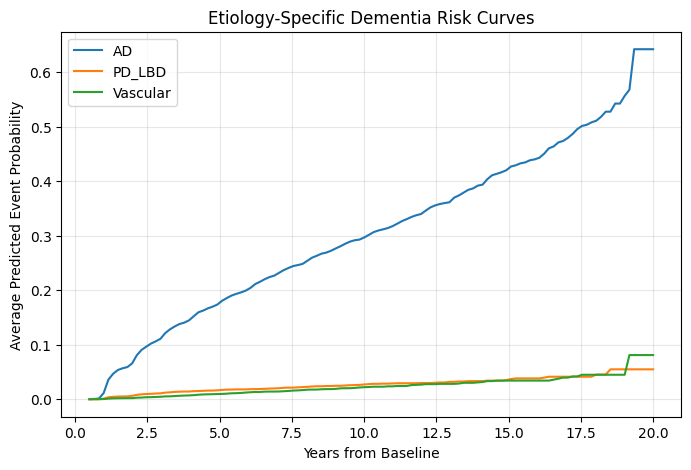

In [220]:
plt.figure(figsize=(8, 5))

for label in ["AD", "PD_LBD", "Vascular"]:
    if label in risk_curve_df.columns:
        plt.plot(risk_curve_df.index, risk_curve_df[label], label=label)

plt.xlabel("Years from Baseline")
plt.ylabel("Average Predicted Event Probability")
plt.title("Etiology-Specific Dementia Risk Curves")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [221]:
milestone_years = [5, 10, 15]

etiology_risk_table = pd.DataFrame(index=milestone_years)

for label in risk_curve_df.columns:
    etiology_risk_table[label] = [
        float(risk_curve_df[label].iloc[np.argmin(np.abs(risk_curve_df.index - yr))])
        for yr in milestone_years
    ]

etiology_risk_table.index.name = "Years"
display(etiology_risk_table)

,AD,PD_LBD,Vascular
Years,,,
5,0.173608,0.016271,0.009504
10,0.296620,0.027073,0.022071
15,0.419952,0.035010,0.034141


Step 2 — Risk stratification survival curves

This uses your bootstrapped 5-year risk and shows whether the model separates people into low / medium / high risk groups.

Cell E — Merge predicted risk into analysis dataframe if needed

In [ ]:
# Step 2: Risk stratification groups

if "analysis_df" not in globals():
    if "model_df" in globals() and "uncertainty_df" in globals():
        analysis_df = model_df.merge(
            uncertainty_df[["NACCID", "risk_5y_mean", "risk_5y_std", "confidence_score"]],
            on="NACCID",
            how="left"
        )
    else:
        raise ValueError("Need analysis_df or both model_df and uncertainty_df.")

# creaing risk groups using tertiles
analysis_df["risk_group_3"] = pd.qcut(
    analysis_df["risk_5y_mean"],
    q=3,
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

print(analysis_df["risk_group_3"].value_counts(dropna=False))

risk_group_3
Low Risk       9018
High Risk      9018
Medium Risk    9016
Name: count, dtype: int64


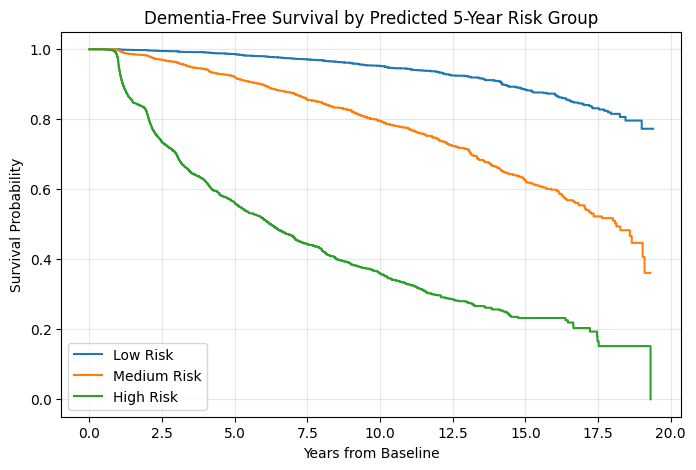

In [223]:
plt.figure(figsize=(8, 5))
kmf = KaplanMeierFitter()

for grp in ["Low Risk", "Medium Risk", "High Risk"]:
    tmp = analysis_df[analysis_df["risk_group_3"] == grp].copy()

    kmf.fit(
        durations=tmp["time_to_event"],
        event_observed=tmp["event_any_dementia"],
        label=grp
    )
    kmf.plot_survival_function(ci_show=False)

plt.title("Dementia-Free Survival by Predicted 5-Year Risk Group")
plt.xlabel("Years from Baseline")
plt.ylabel("Survival Probability")
plt.grid(True, alpha=0.3)
plt.show()

In [224]:
risk_group_summary = analysis_df.groupby("risk_group_3").agg(
    n=("NACCID", "count"),
    mean_predicted_5y_risk=("risk_5y_mean", "mean"),
    observed_event_rate=("event_any_dementia", "mean"),
    mean_followup=("time_to_event", "mean")
)

display(risk_group_summary)

C:\Users\branjan\AppData\Local\Temp\ipykernel_18456\1494596913.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  risk_group_summary = analysis_df.groupby("risk_group_3").agg(


,n,mean_predicted_5y_risk,observed_event_rate,mean_followup
risk_group_3,,,,
Low Risk,9018,0.087325,0.034043,6.251442
Medium Risk,9016,0.139340,0.119343,5.526491
High Risk,9018,0.314339,0.384564,3.575294


Step 3 — Explain uncertainty

creates plots showing who becomes uncertain.

In [ ]:
# Step 3: Uncertainty explanation

needed_cols = ["risk_5y_std", "confidence_score"]
for c in needed_cols:
    if c not in analysis_df.columns:
        raise ValueError(f"{c} not found in analysis_df")

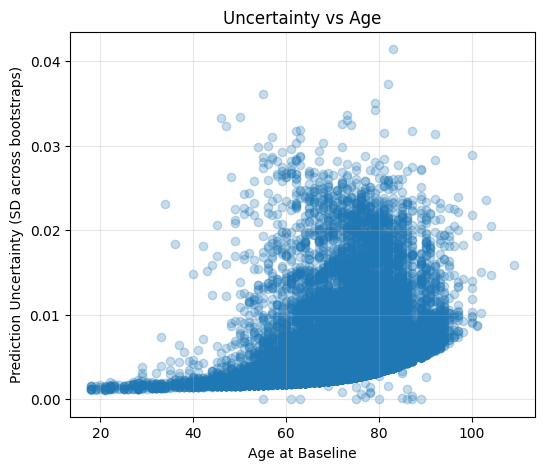

In [226]:
plt.figure(figsize=(6, 5))
plt.scatter(
    analysis_df["NACCAGE"],
    analysis_df["risk_5y_std"],
    alpha=0.25
)
plt.xlabel("Age at Baseline")
plt.ylabel("Prediction Uncertainty (SD across bootstraps)")
plt.title("Uncertainty vs Age")
plt.grid(True, alpha=0.3)
plt.show()

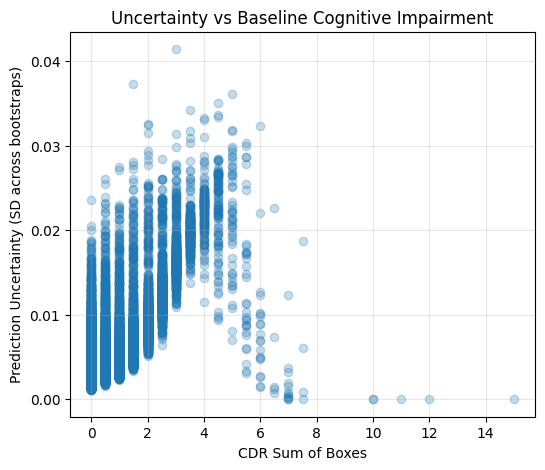

In [227]:
plt.figure(figsize=(6, 5))
plt.scatter(
    analysis_df["CDRSUM"],
    analysis_df["risk_5y_std"],
    alpha=0.25
)
plt.xlabel("CDR Sum of Boxes")
plt.ylabel("Prediction Uncertainty (SD across bootstraps)")
plt.title("Uncertainty vs Baseline Cognitive Impairment")
plt.grid(True, alpha=0.3)
plt.show()

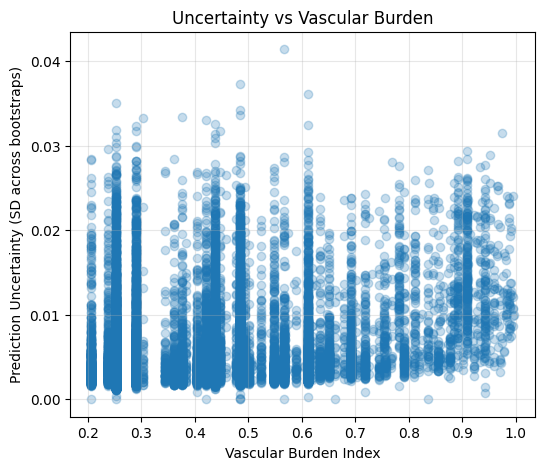

In [228]:
if "vascular_burden_index" in analysis_df.columns:
    plt.figure(figsize=(6, 5))
    plt.scatter(
        analysis_df["vascular_burden_index"],
        analysis_df["risk_5y_std"],
        alpha=0.25
    )
    plt.xlabel("Vascular Burden Index")
    plt.ylabel("Prediction Uncertainty (SD across bootstraps)")
    plt.title("Uncertainty vs Vascular Burden")
    plt.grid(True, alpha=0.3)
    plt.show()
else:
    print("vascular_burden_index not found in analysis_df")

In [229]:
def make_binned_summary(df, xcol, ycol="risk_5y_std", bins=5):
    tmp = df[[xcol, ycol]].dropna().copy()
    tmp["bin"] = pd.qcut(tmp[xcol], q=bins, duplicates="drop")
    out = tmp.groupby("bin").agg(
        n=(xcol, "count"),
        x_mean=(xcol, "mean"),
        y_mean=(ycol, "mean")
    )
    return out

display(make_binned_summary(analysis_df, "NACCAGE"))
display(make_binned_summary(analysis_df, "CDRSUM"))

if "vascular_burden_index" in analysis_df.columns:
    display(make_binned_summary(analysis_df, "vascular_burden_index"))

C:\Users\branjan\AppData\Local\Temp\ipykernel_18456\4241580833.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  out = tmp.groupby("bin").agg(


,n,x_mean,y_mean
bin,,,
"(17.999, 64.0]",6073,57.403590,0.003757
"(64.0, 69.0]",5398,67.049278,0.004293
"(69.0, 74.0]",5815,71.938435,0.005019
"(74.0, 79.0]",4728,76.853426,0.006337
"(79.0, 109.0]",5038,84.259627,0.007790


C:\Users\branjan\AppData\Local\Temp\ipykernel_18456\4241580833.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  out = tmp.groupby("bin").agg(


,n,x_mean,y_mean
bin,,,
"(-0.001, 0.5]",20368,0.105239,0.003852
"(0.5, 1.0]",2275,1.000000,0.005711
"(1.0, 15.0]",4409,2.382286,0.012006


C:\Users\branjan\AppData\Local\Temp\ipykernel_18456\4241580833.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  out = tmp.groupby("bin").agg(


,n,x_mean,y_mean
bin,,,
"(0.205, 0.252]",8152,0.247900,0.004645
"(0.252, 0.289]",3934,0.289172,0.004959
"(0.289, 0.439]",5254,0.422379,0.005118
"(0.439, 0.485]",4981,0.483116,0.005263
"(0.485, 0.997]",4731,0.668967,0.007164


Step 4 — Age × vascular burden risk heatmap

In [ ]:
# Step 4: Age x vascular burden risk landscape

# detecting main Cox model
main_cph = None
for name in ["cph", "cox_model", "cox_vbi", "cph_any"]:
    if name in globals():
        main_cph = globals()[name]
        print("Using main Cox model:", name)
        break

if main_cph is None:
    raise ValueError("Could not find main Cox model. Rename main_cph manually.")

main_model_cols = list(main_cph.params_.index)

reference = {}
for col in main_model_cols:
    if col in analysis_df.columns:
        vals = pd.to_numeric(analysis_df[col], errors="coerce")
        if vals.notna().sum() > 0:
            reference[col] = float(vals.median())
        else:
            reference[col] = 0.0
    else:
        reference[col] = 0.0

if "SEX" in analysis_df.columns and "SEX" in reference:
    sex_mode = analysis_df["SEX"].mode()
    if len(sex_mode) > 0:
        reference["SEX"] = float(sex_mode.iloc[0])

age_grid = np.linspace(
    analysis_df["NACCAGE"].quantile(0.05),
    analysis_df["NACCAGE"].quantile(0.95),
    40
)

if "vascular_burden_index" not in analysis_df.columns:
    raise ValueError("vascular_burden_index not found in analysis_df")

vbi_grid = np.linspace(
    analysis_df["vascular_burden_index"].quantile(0.05),
    analysis_df["vascular_burden_index"].quantile(0.95),
    40
)

grid_rows = []
for age in age_grid:
    for vbi in vbi_grid:
        row = reference.copy()
        if "NACCAGE" in row:
            row["NACCAGE"] = float(age)
        if "vascular_burden_index" in row:
            row["vascular_burden_index"] = float(vbi)
        grid_rows.append(row)

grid_df = pd.DataFrame(grid_rows)[main_model_cols].copy()

for col in grid_df.columns:
    grid_df[col] = pd.to_numeric(grid_df[col], errors="coerce").fillna(0)

# predict 5-year risk
surv_grid = main_cph.predict_survival_function(grid_df, times=[5.0])
risk_5y_grid = 1 - surv_grid.T.iloc[:, 0].values

risk_matrix = risk_5y_grid.reshape(len(age_grid), len(vbi_grid))

Using main Cox model: cph


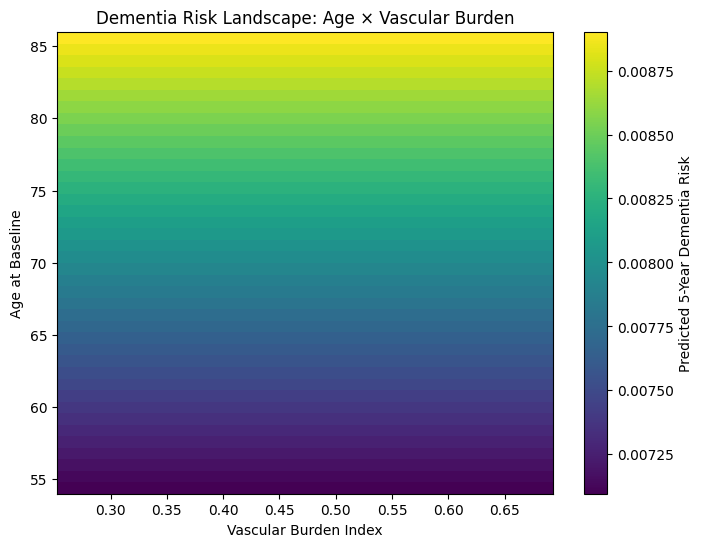

In [231]:
plt.figure(figsize=(8, 6))
im = plt.imshow(
    risk_matrix,
    aspect="auto",
    origin="lower",
    extent=[vbi_grid.min(), vbi_grid.max(), age_grid.min(), age_grid.max()]
)
plt.colorbar(im, label="Predicted 5-Year Dementia Risk")
plt.xlabel("Vascular Burden Index")
plt.ylabel("Age at Baseline")
plt.title("Dementia Risk Landscape: Age × Vascular Burden")
plt.show()

In [232]:
etiology_risk_table.to_csv("etiology_risk_table.csv")
risk_group_summary.to_csv("risk_group_summary.csv")

if "risk_curve_df" in globals():
    risk_curve_df.to_csv("etiology_risk_curves_full.csv")

print("Saved CSV outputs.")

Saved CSV outputs.
